# Pronóstico de caudales altos en el río Tebicuary — estación Villa Florida

Diplomado en Machine Learning y Deep Learning Aplicado — FIUNA · Proyecto Final Integrador (M7)

Objetivo: pronosticar el caudal diario en Villa Florida con 1, 3 y 5 días de anticipación, con intervalos de confianza, y alertar la superación del caudal de 10 % de permanencia (Q10 de la curva de permanencia = 823 m³/s), a partir del caudal observado y de la precipitación media areal antecedente de la cuenca.

Machine learning y deep learning en este trabajo: se usa machine learning (gradient boosting, LightGBM), que es el estado del arte para datos tabulares como estos (una fila por día, ~18 variables, ~7 400 días de entrenamiento). No se usa deep learning: una prueba con una red neuronal densa en el mismo pipeline no mejoró la precisión (ver `analisis_complementarios/prueba_red_neuronal.py`), y las redes necesitan más datos que los disponibles.

Alcance: el pronóstico se emite para caudales medios y altos. Los estiajes (caudal superado más del 75 % del tiempo, < 112 m³/s) tienen mayor variabilidad relativa y un régimen que cambió en el período reciente; se deja constancia de ello y no se pronostican.

Flujo del notebook:
1. Datos, control de calidad y precipitación media areal por Thiessen dinámico.
2. Análisis exploratorio, variables y partición temporal (entrenamiento 1974–2002, test 2013–2023).
3. Línea base (persistencia), ventanas de lluvia y comparación de modelos.
4. Optimización con validación cruzada temporal y modelos finales a 1, 3 y 5 días.
5. Evaluación: serie completa, alcance, extremos y desfase.
6. Intervalos de confianza (regresión cuantílica con recalibración conformal).
7. Alerta de crecidas: probabilidad de superar el caudal de 10 % de permanencia.
8. Explicabilidad (SHAP), retorno de la inversión (3 escenarios), guardado del modelo e inferencia, muestra de datos.

## 1. Configuración

In [1]:
import warnings, os, glob
from itertools import compress
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point, MultiPoint, Polygon
from shapely.ops import voronoi_diagram
import joblib, shap

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
SEED = 42
np.random.seed(SEED)
# Reproducibilidad: LightGBM determinista (mismo resultado en cualquier computadora)
LGB_DET = dict(deterministic=True, force_row_wise=True, n_jobs=2)

RAW = 'data/raw'
PROC = 'data/processed'
FIG = 'figuras'
os.makedirs(PROC, exist_ok=True); os.makedirs(FIG, exist_ok=True)

# Estilo de gráficos: ejes y grilla recesivos, líneas finas
C_OBS, C_MOD, C_PERS, C_P = '#2a78d6', '#eb6834', '#8a8984', '#1baf7a'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#333', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'lines.linewidth': 1.5, 'font.size': 9, 'legend.frameon': False})

/home/claude/rev/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Carga y limpieza de datos

Formato de los archivos: `día mes año valor`. El valor `-1` indica dato faltante. Se detectó un bloque de fechas duplicadas en San Juan Bautista (1–10 ene 2018) con valores idénticos; se conserva la primera ocurrencia.

No se completan faltantes con estaciones vecinas: el Thiessen dinámico redistribuye el área de la estación faltante entre las disponibles, lo que evita introducir series sintéticas que suavizan los extremos.

In [2]:
EST = {  # lat, lon — Estaciones_Pluviometricas.xlsx (DMH)
    'Paraguari': (-25.627040, -57.145998), 'Villarrica': (-25.753987, -56.437998),
    'Coronel_Oviedo': (-25.484017, -56.377995), 'Quyquyho': (-26.217039, -56.983002),
    'Pilar': (-26.881037, -58.318002), 'San_Juan_Bautista': (-26.669977, -57.133996),
    'Caazapa': (-26.174962, -56.355000), 'Encarnacion': (-27.225982, -55.837004)}
VF_GAUGE = (-26.392694, -57.129654)
NOMBRE = {'Paraguari': 'Paraguarí', 'Villarrica': 'Villarrica', 'Coronel_Oviedo': 'Coronel Oviedo', 'Quyquyho': 'Quyquyho',
          'Pilar': 'Pilar', 'San_Juan_Bautista': 'San Juan Bautista', 'Caazapa': 'Caazapá', 'Encarnacion': 'Encarnación'}

def leer_serie(path):
    d = pd.read_csv(path, sep=r'\s+', header=None, names=['d', 'm', 'y', 'v'])
    d.index = pd.to_datetime(dict(year=d.y, month=d.m, day=d.d))
    n_dup = d.index.duplicated().sum()
    s = d.v[~d.index.duplicated(keep='first')]
    return s.where(s >= 0), n_dup   # negativos (-1) -> NaN

P, dups = {}, {}
for k in EST:
    P[k], dups[k] = leer_serie(f'{RAW}/Precipitaciones/{k}.txt')
P = pd.DataFrame(P).asfreq('D')
Q, _ = leer_serie(f'{RAW}/Caudales/Caudal Villa Florida.txt')
Q = Q.asfreq('D').rename('Q')

print('Período:', P.index.min().date(), '→', P.index.max().date(), f'({len(P)} días)')
print('Fechas duplicadas eliminadas:', {k: v for k, v in dups.items() if v})
print('\nFaltantes (%):')
print(pd.concat([P, Q], axis=1).isna().mean().mul(100).round(1).to_string())

Período: 1974-01-01 → 2023-08-23 (18132 días)
Fechas duplicadas eliminadas: {'San_Juan_Bautista': np.int64(10)}

Faltantes (%):
Paraguari            40.7
Villarrica            0.7
Coronel_Oviedo       30.3
Quyquyho              2.5
Pilar                 1.3
San_Juan_Bautista     2.3
Caazapa               2.7
Encarnacion           1.5
Q                    38.6


### Series duplicadas: Quyquyho y Caazapá

Las series originales de Quyquyho y Caazapá son idénticas día a día entre 1974 y 2016 (en las series entregadas por la fuente); desde 2017 se separan. Una de ellas fue completada con la otra. Para no contar dos veces la misma lluvia en el Thiessen, se trata Caazapá como faltante en 1974–2016 (tratamiento D2): en ese período su área se redistribuye entre las estaciones vecinas. La prueba de sensibilidad (Quyquyho o Caazapá como faltante, análisis complementario) dio resultados equivalentes y ambas mejoran levemente respecto a mantener la duplicación.

In [3]:
_m = P['Quyquyho'].notna() & P['Caazapa'].notna()
iguales = (P['Quyquyho'][_m] == P['Caazapa'][_m]).groupby(P.index[_m].year).mean()
print('Fracción de días idénticos Quyquyho = Caazapá por año:')
print(iguales.round(2).to_dict())
P_orig = P.copy()   # series tal como fueron entregadas (para el escenario B)
P.loc[P.index.year <= 2016, 'Caazapa'] = np.nan   # tratamiento D2
print(f"Faltantes de Caazapá tras el tratamiento: {P['Caazapa'].isna().mean():.1%}")

Fracción de días idénticos Quyquyho = Caazapá por año:
{1974: 1.0, 1975: 1.0, 1976: 1.0, 1977: 1.0, 1978: 1.0, 1979: 1.0, 1980: 1.0, 1982: 1.0, 1983: 1.0, 1984: 1.0, 1985: 1.0, 1986: 1.0, 1987: 1.0, 1988: 1.0, 1989: 1.0, 1990: 1.0, 1991: 1.0, 1992: 1.0, 1993: 1.0, 1994: 1.0, 1995: 1.0, 1996: 1.0, 1997: 1.0, 1998: 1.0, 1999: 1.0, 2000: 1.0, 2001: 1.0, 2002: 1.0, 2003: 1.0, 2004: 1.0, 2005: 1.0, 2006: 1.0, 2007: 1.0, 2008: 1.0, 2009: 1.0, 2010: 1.0, 2011: 1.0, 2012: 1.0, 2013: 1.0, 2014: 1.0, 2015: 1.0, 2016: 1.0, 2017: 0.72, 2018: 0.7, 2019: 0.7, 2020: 0.75, 2021: 0.72, 2022: 0.75, 2023: 0.73}
Faltantes de Caazapá tras el tratamiento: 86.9%


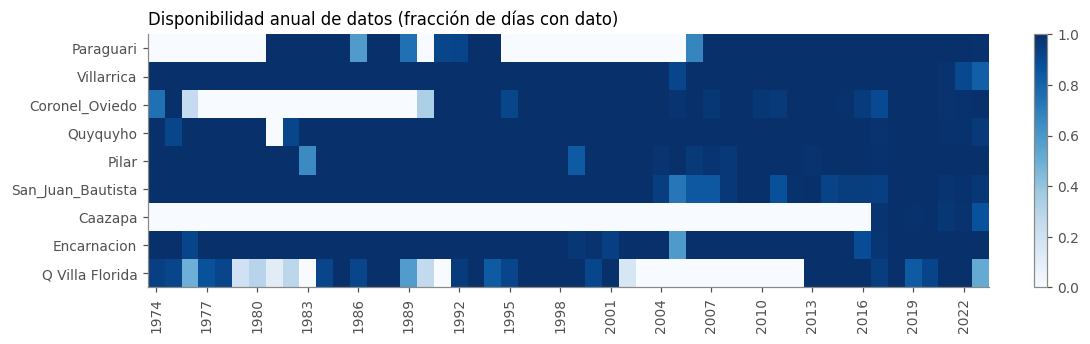

In [4]:
disp = pd.concat([P, Q.rename('Q Villa Florida')], axis=1).notna().groupby(P.index.year).mean()
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(disp.T.values, aspect='auto', cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
ax.set_yticks(range(disp.shape[1])); ax.set_yticklabels(disp.columns)
ax.set_xticks(range(0, len(disp), 3)); ax.set_xticklabels(disp.index[::3], rotation=90)
ax.grid(False); ax.set_title('Disponibilidad anual de datos (fracción de días con dato)', loc='left')
plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout(); plt.savefig(f'{FIG}/disponibilidad.png', dpi=150); plt.show()

El caudal en Villa Florida tiene un vacío continuo entre 2003 y 2012. Eso define la partición temporal: entrenamiento 1974–2002 y test 2013–2023, sin mezclar períodos.

## 3. Precipitación media areal — Thiessen dinámico

Los polígonos de Thiessen se recortan con la cuenca de aporte a Villa Florida (proyección UTM 21S). Para cada día se recalculan los pesos usando únicamente las estaciones con dato; las combinaciones se guardan en caché.

In [5]:
cuenca = gpd.read_file(f'{RAW}/cuenca/VillaFlorida.shp').to_crs(32721)
# Disolver subcuencas y eliminar huecos internos (artefactos de la disolución)
_g = cuenca.geometry.union_all().buffer(50).buffer(-50)
_g = max(_g.geoms, key=lambda p: p.area) if _g.geom_type == 'MultiPolygon' else _g
geom = Polygon(_g.exterior)
A_KM2 = geom.area / 1e6
est_gs = gpd.GeoSeries([Point(lon, lat) for lat, lon in EST.values()], index=list(EST), crs=4326).to_crs(32721)
print(f'Área de la cuenca: {A_KM2:,.0f} km²')

_cache = {}
def pesos_thiessen(mask):
    key = tuple(bool(m) for m in mask)
    if key in _cache: return _cache[key]
    names = list(compress(EST, key))
    w, cells = pd.Series(0.0, index=list(EST)), {}
    if len(names) == 1:
        w[names[0]] = 1.0
    elif len(names) > 1:
        pts = est_gs[names]
        vor = voronoi_diagram(MultiPoint(list(pts)), envelope=geom.buffer(3e5))
        for cell in vor.geoms:
            for n in names:
                if cell.contains(pts[n]):
                    cells[n] = cell.intersection(geom)
                    w[n] = cells[n].area / geom.area
    _cache[key] = (w, cells)
    return w, cells

w_full, cells_full = pesos_thiessen([True] * len(EST))
print('Pesos de Thiessen con la red completa:')
print(w_full.sort_values(ascending=False).round(3).to_string())

Área de la cuenca: 20,987 km²
Pesos de Thiessen con la red completa:
Caazapa              0.422
Quyquyho             0.162
Villarrica           0.145
San_Juan_Bautista    0.113
Coronel_Oviedo       0.066
Encarnacion          0.065
Paraguari            0.026
Pilar                0.000


### Mapa de la cuenca y polígonos de Thiessen

Coordenadas UTM 21S en km; norte hacia arriba (flecha N), barra de escala de 50 km.

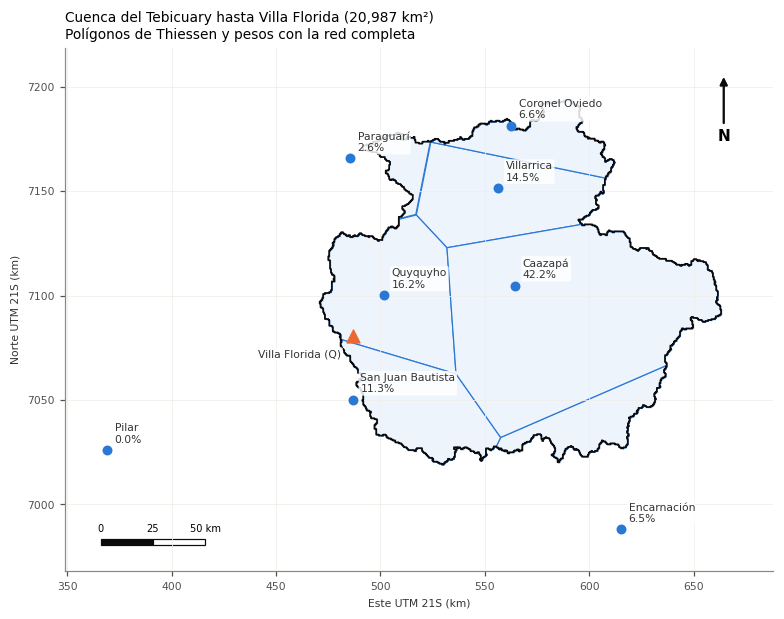

In [6]:
from matplotlib.patches import FancyArrow, Rectangle
vf = gpd.GeoSeries([Point(VF_GAUGE[1], VF_GAUGE[0])], crs=4326).to_crs(32721)
XMIN, YMIN, XMAX, YMAX = geom.buffer(25e3).union(est_gs.union_all().buffer(20e3)).bounds

def dibujar_mapa(ax, cells, w, activos, titulo, etiquetas=True):
    for n, c in cells.items():
        if not c.is_empty:
            gpd.GeoSeries([c], crs=32721).plot(ax=ax, facecolor='#eef4fc', edgecolor='#2a78d6', linewidth=0.8)
    gpd.GeoSeries([geom], crs=32721).boundary.plot(ax=ax, color='#0b0b0b', linewidth=1.1)
    for n, p in est_gs.items():
        on = activos[list(EST).index(n)]
        ax.scatter(p.x, p.y, s=28 if on else 22, color=C_OBS if on else 'white', edgecolor=C_OBS if on else '#8a8984',
                   linewidth=1.2, zorder=3, marker='o' if on else 'X')
        if etiquetas:
            txt = f'{NOMBRE[n]}\n{w[n]:.1%}' if on else f'{NOMBRE[n]}\n(sin dato)'
            ax.annotate(txt, (p.x, p.y), xytext=(5, 5), textcoords='offset points', fontsize=7, color='#333',
                        bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
    ax.scatter(vf.x[0], vf.y[0], s=70, marker='^', color=C_MOD, zorder=4)
    if etiquetas:
        ax.annotate('Villa Florida (Q)', (vf.x[0], vf.y[0]), xytext=(-8, -14), textcoords='offset points', fontsize=7,
                    ha='right', color='#333', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
    ax.set_xlim(XMIN, XMAX); ax.set_ylim(YMIN, YMAX); ax.set_aspect('equal')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:.0f}'))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:.0f}'))
    ax.set_xlabel('Este UTM 21S (km)', fontsize=7); ax.set_ylabel('Norte UTM 21S (km)', fontsize=7)
    ax.tick_params(labelsize=7); ax.grid(True, color='#eeeeea', lw=0.5)
    # flecha norte y barra de escala
    dx, dy = XMAX - XMIN, YMAX - YMIN
    ax.annotate('N', xy=(XMAX - 0.07*dx, YMAX - 0.05*dy), xytext=(XMAX - 0.07*dx, YMAX - 0.17*dy),
                ha='center', va='center', fontsize=10, fontweight='bold',
                arrowprops=dict(arrowstyle='-|>', color='#0b0b0b', lw=1.5))
    x0, y0 = XMIN + 0.05*dx, YMIN + 0.05*dy
    for i in range(2):
        ax.add_patch(Rectangle((x0 + i*25e3, y0), 25e3, 0.012*dy, facecolor='#0b0b0b' if i == 0 else 'white', edgecolor='#0b0b0b', lw=0.8))
    for i, lab in enumerate(['0', '25', '50 km']):
        ax.text(x0 + i*25e3, y0 + 0.025*dy, lab, ha='center', fontsize=6.5)
    ax.set_title(titulo, loc='left', fontsize=9)

fig, ax = plt.subplots(figsize=(7.2, 7.2))
dibujar_mapa(ax, cells_full, w_full, [True]*len(EST), f'Cuenca del Tebicuary hasta Villa Florida ({A_KM2:,.0f} km²)\nPolígonos de Thiessen y pesos con la red completa')
plt.tight_layout(); plt.savefig(f'{FIG}/mapa_thiessen.png', dpi=170); plt.show()

### Thiessen dinámico: ejemplos

Cuando una estación no tiene dato, su polígono desaparece y el área se reparte entre las vecinas. Se muestran dos situaciones reales del registro: la ausencia simultánea de Paraguarí y Coronel Oviedo (frecuente en los años 80) y la ausencia de Caazapá, la estación de mayor peso.

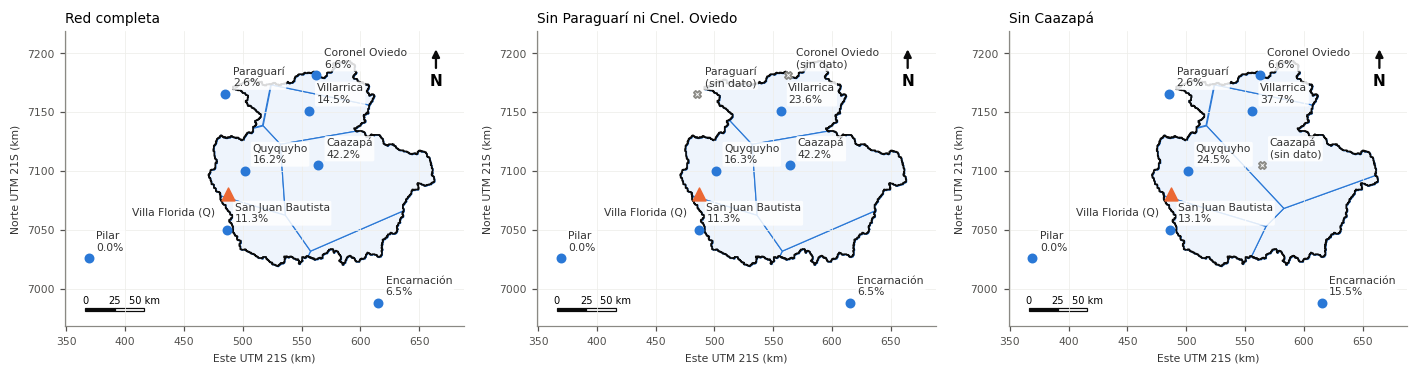

                   Red completa  Sin Paraguarí ni Cnel. Oviedo  Sin Caazapá
Paraguari                 0.026                          0.000        0.026
Villarrica                0.145                          0.236        0.377
Coronel_Oviedo            0.066                          0.000        0.066
Quyquyho                  0.162                          0.163        0.245
Pilar                     0.000                          0.000        0.000
San_Juan_Bautista         0.113                          0.113        0.131
Caazapa                   0.422                          0.422        0.000
Encarnacion               0.065                          0.065        0.155


In [7]:
casos = [('Red completa', [True]*8),
         ('Sin Paraguarí ni Cnel. Oviedo', [n not in ('Paraguari', 'Coronel_Oviedo') for n in EST]),
         ('Sin Caazapá', [n != 'Caazapa' for n in EST])]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.8))
for ax, (tit, m) in zip(axs, casos):
    w_c, cells_c = pesos_thiessen(m)
    dibujar_mapa(ax, cells_c, w_c, m, tit, etiquetas=True)
plt.tight_layout(); plt.savefig(f'{FIG}/thiessen_dinamico.png', dpi=160); plt.show()
print(pd.DataFrame({t: pesos_thiessen(m)[0] for t, m in casos}).round(3))

In [8]:
disp_mask = P.notna().values
W = np.array([pesos_thiessen(m)[0].values for m in disp_mask])
Pmed = pd.Series((W * np.nan_to_num(P.values)).sum(1), index=P.index)
Pmed[W.sum(1) == 0] = np.nan
cob_red = pd.Series(disp_mask @ w_full.values, index=P.index)  # fracción del área con su estación original disponible

serie = pd.DataFrame({'Pmed': Pmed, 'cob_red': cob_red, 'Q': Q})
serie.join(P).to_csv(f'{PROC}/serie_diaria.csv', index_label='fecha')
print(f'Combinaciones de estaciones distintas: {len(_cache)}')
print(f'Precipitación media anual de la cuenca: {Pmed.resample("YE").sum(min_count=330).mean():.0f} mm')
print(f'Días con cobertura original < 80 % del área: {(cob_red < 0.8).mean():.1%}')

Combinaciones de estaciones distintas: 50
Precipitación media anual de la cuenca: 1668 mm
Días con cobertura original < 80 % del área: 86.9%


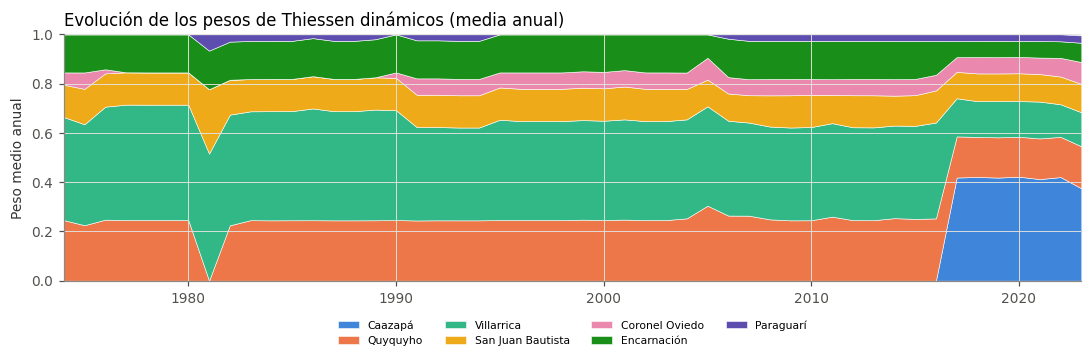

In [9]:
Wdf = pd.DataFrame(W, index=P.index, columns=list(EST))
w_anual = Wdf.groupby(Wdf.index.year).mean()
orden_w = w_full.sort_values(ascending=False).index[:7]
paleta = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7']
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.stackplot(w_anual.index, [w_anual[c] for c in orden_w], labels=[NOMBRE[c] for c in orden_w], colors=paleta, alpha=0.9, edgecolor='white', linewidth=0.4)
ax.set_ylim(0, 1); ax.set_xlim(w_anual.index.min(), w_anual.index.max())
ax.set_ylabel('Peso medio anual'); ax.legend(ncol=4, fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.set_title('Evolución de los pesos de Thiessen dinámicos (media anual)', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/pesos_dinamicos.png', dpi=150); plt.show()

### Tratamiento de los faltantes (-1): comparación de escenarios

- Escenario A (adoptado): -1 → faltante; Thiessen dinámico con las estaciones disponibles.
- Escenario B: -1 tratado como 0 mm con pesos fijos (error frecuente al leer estas series).

{'dias_alguna_faltante': 0.879053606882859, 'Pmed_anual_A': 1668.0575729973884, 'Pmed_anual_B': 1564.5346619442814, 'dif_diaria_max': 64.25750885402853, 'anio_max_dif': 1981, 'dif_anual_max': 903.0934026507}


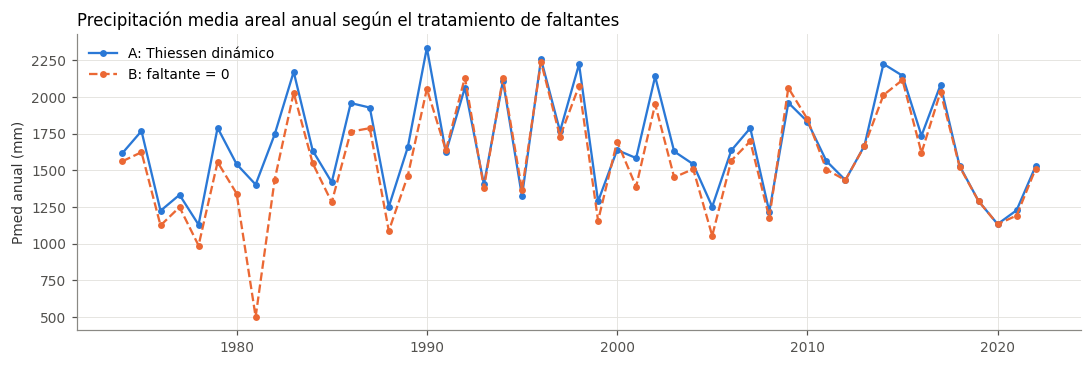

In [10]:
Pmed_B = pd.Series(np.nan_to_num(P_orig.values) @ w_full.values, index=P.index)   # -1 -> 0, pesos fijos, series originales
anual = pd.DataFrame({'A: Thiessen dinámico': Pmed.resample('YE').sum(min_count=330),
                      'B: faltante = 0': Pmed_B.resample('YE').sum(min_count=330)})
anual.index = anual.index.year
dif = Pmed_B - Pmed
R = {}   # resultados clave para la memoria
R['faltantes'] = {'dias_alguna_faltante': float(P.isna().any(axis=1).mean()),
                  'Pmed_anual_A': float(anual.iloc[:, 0].mean()), 'Pmed_anual_B': float(anual.iloc[:, 1].mean()),
                  'dif_diaria_max': float(dif.abs().max()), 'anio_max_dif': int((anual.iloc[:, 0] - anual.iloc[:, 1]).idxmax()),
                  'dif_anual_max': float((anual.iloc[:, 0] - anual.iloc[:, 1]).max())}
print(R['faltantes'])
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(anual.index, anual.iloc[:, 0], color=C_OBS, marker='o', ms=3.5, label=anual.columns[0])
ax.plot(anual.index, anual.iloc[:, 1], color=C_MOD, marker='o', ms=3.5, ls='--', label=anual.columns[1])
ax.set_ylabel('Pmed anual (mm)'); ax.legend(loc='upper left')
ax.set_title('Precipitación media areal anual según el tratamiento de faltantes', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/faltantes_AB.png', dpi=150); plt.show()

## 4. Análisis exploratorio

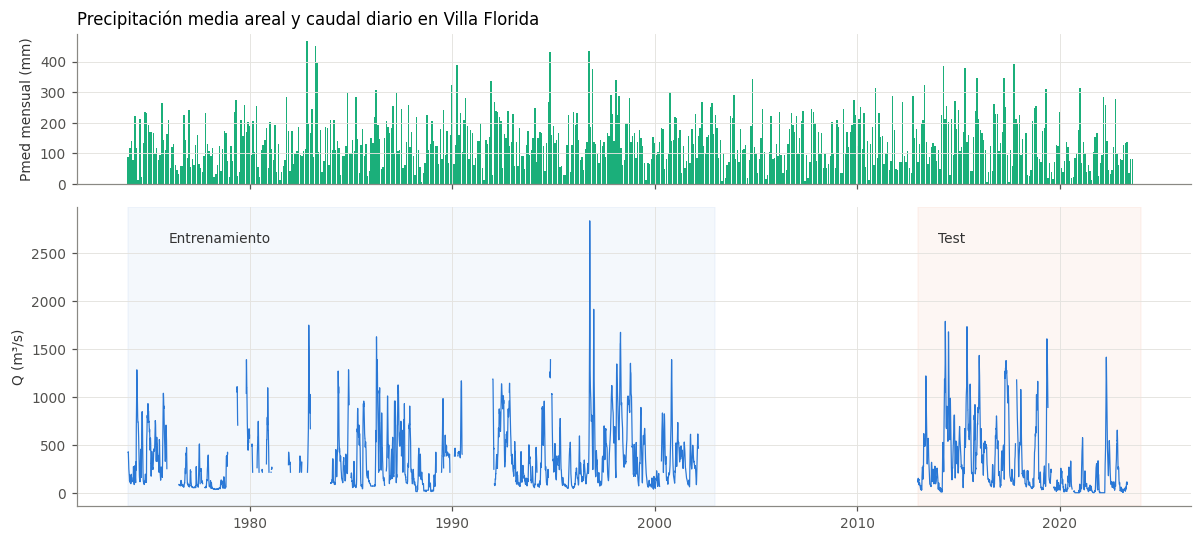

        count   mean    std  min   25%    50%    75%     max
Pmed  18131.0    4.5   11.0  0.0   0.0    0.0    2.9   166.9
Q     11139.0  341.1  320.3  0.9  95.5  232.7  494.5  2836.2


In [11]:
fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={'height_ratios': [1, 2]})
pm = Pmed.resample('MS').sum()
axs[0].bar(pm.index, pm.values, width=25, color=C_P)
axs[0].set_ylabel('Pmed mensual (mm)')
axs[1].plot(Q.index, Q.values, color=C_OBS, lw=0.8)
axs[1].set_ylabel('Q (m³/s)')
axs[1].axvspan(pd.Timestamp('1974-01-01'), pd.Timestamp('2002-12-31'), color='#2a78d6', alpha=0.05)
axs[1].axvspan(pd.Timestamp('2013-01-01'), pd.Timestamp('2023-12-31'), color='#eb6834', alpha=0.06)
axs[1].text(pd.Timestamp('1976-01-01'), Q.max() * 0.92, 'Entrenamiento', color='#333')
axs[1].text(pd.Timestamp('2014-01-01'), Q.max() * 0.92, 'Test', color='#333')
axs[0].set_title('Precipitación media areal y caudal diario en Villa Florida', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/series.png', dpi=150); plt.show()

print(serie[['Pmed', 'Q']].describe().round(1).T)

### Tiempo de respuesta de la cuenca

Correlación entre la lluvia del día *t* y la variación del caudal (Δlog Q) *k* días después. El máximo indica el retardo típico entre lluvia y respuesta en Villa Florida, y orienta las ventanas de acumulación a evaluar.

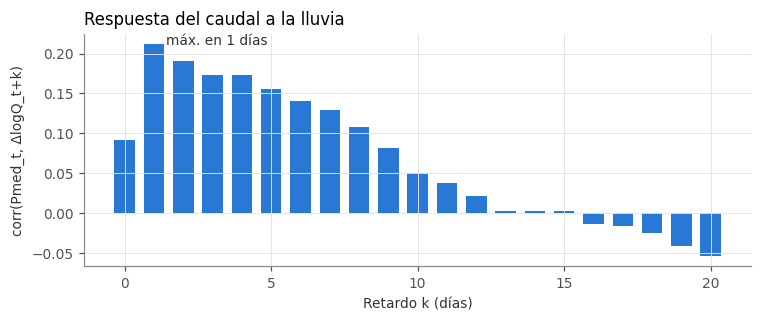

Correlación por retardo: [0.092 0.212 0.19  0.173 0.173 0.156 0.14  0.129 0.107 0.082 0.05  0.037]


In [12]:
dlq = np.log(serie.Q).diff()
lags = range(0, 21)
cc = [serie.Pmed.corr(dlq.shift(-k)) for k in lags]
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(list(lags), cc, color=C_OBS, width=0.7)
k_max = int(np.argmax(cc))
ax.annotate(f'máx. en {k_max} días', (k_max, cc[k_max]), xytext=(8, 0), textcoords='offset points', color='#333')
ax.set_xlabel('Retardo k (días)'); ax.set_ylabel('corr(Pmed_t, ΔlogQ_t+k)')
ax.set_title('Respuesta del caudal a la lluvia', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/correlacion_retardo.png', dpi=150); plt.show()
print('Correlación por retardo:', np.round(cc[:12], 3))

## 5. Feature engineering

Momento de emisión: la mañana del día t+1, cuando ya están disponibles la lectura pluviométrica asignada al día t (convención DMH) y el caudal medio del día t. Variables disponibles en ese momento:

| Grupo | Variables |
|---|---|
| Caudal | log Q en t, t-1, t-2, t-3, t-7; Δlog Q a 1 y 3 días |
| Lluvia acumulada | P1, P3, P5, P7, P10, P15, P30 (mm, suma de *k* días hasta t) |
| Lluvia rezagada | P(t-1), P(t-2) |
| Humedad antecedente | API (índice de precipitación antecedente, k = 0.9) |
| Estacionalidad | mes (categórica → One-Hot) |

Objetivo: `y = log Q(t+h) − log Q(t)`. Modelar la variación relativa en lugar del caudal absoluto permite a los árboles generalizar a caudales fuera del rango de entrenamiento; el caudal se reconstruye como `Q(t) · exp(ŷ)`.

No se usa lluvia futura, de modo que el modelo es operable con los datos que la red ya produce.

In [13]:
VENT = [1, 3, 5, 7, 10, 15, 30]
API_K = 0.9

def construir_features(df):
    """df: índice diario, columnas Pmed y Q. Devuelve la matriz de features."""
    X = pd.DataFrame(index=df.index)
    lq = np.log(df['Q'])
    for l in [0, 1, 2, 3, 7]:
        X[f'lQ_{l}'] = lq.shift(l)
    X['dlQ_1'] = lq - lq.shift(1)
    X['dlQ_3'] = lq - lq.shift(3)
    for k in VENT:
        X[f'P{k}'] = df['Pmed'].rolling(k, min_periods=k).sum()
    for l in [1, 2]:
        X[f'P_lag{l}'] = df['Pmed'].shift(l)
    p = df['Pmed'].fillna(0).values
    api = np.zeros(len(p))
    for i in range(1, len(p)):
        api[i] = API_K * api[i - 1] + p[i]
    X['API'] = api
    X['mes'] = df.index.month.astype(str)
    return X

X = construir_features(serie)
QCOLS = ['lQ_0', 'lQ_1', 'lQ_2', 'lQ_3', 'lQ_7', 'dlQ_1', 'dlQ_3']
PCOLS = [f'P{k}' for k in VENT] + ['P_lag1', 'P_lag2', 'API']
ALL_COLS = QCOLS + PCOLS + ['mes']

TRAIN = serie.index.year <= 2002
TEST = serie.index.year >= 2013
Q90 = serie.Q[TRAIN].quantile(0.90)
print(f'Umbral de caudal alto (P90 entrenamiento): {Q90:.0f} m³/s')
X.loc[TEST].dropna().head()

Umbral de caudal alto (P90 entrenamiento): 823 m³/s


,lQ_0,lQ_1,lQ_2,lQ_3,lQ_7,dlQ_1,dlQ_3,P1,P3,P5,P7,P10,P15,P30,P_lag1,P_lag2,API,mes
2013-01-08,4.655453,4.655453,5.020350,4.952280,4.762931,0.000000,-0.296827,0.0,20.105347,29.153821,29.153821,69.593914,82.007249,184.404151,11.453674,8.651674,56.071709,1
2013-01-09,4.762931,4.655453,4.655453,5.020350,4.861377,0.107478,-0.257419,0.0,11.453674,28.257669,29.153821,63.625426,81.760034,182.299129,0.000000,11.453674,50.464538,1
2013-01-10,4.907693,4.762931,4.655453,4.655453,4.907693,0.144762,0.252241,0.0,0.000000,20.105347,29.153821,32.878612,72.039144,181.325723,0.000000,0.000000,45.418084,1
2013-01-11,4.952280,4.907693,4.762931,4.655453,4.934644,0.044587,0.296827,0.0,0.000000,11.453674,28.257669,29.153821,71.626535,142.329653,0.000000,0.000000,40.876276,1
2013-01-12,4.861377,4.952280,4.907693,4.762931,4.952280,-0.090903,0.098446,0.0,0.000000,0.000000,20.105347,29.153821,71.553036,130.587831,0.000000,0.000000,36.788648,1


## 6. Pipeline, métricas y línea base

`ColumnTransformer`: numéricas → imputación por mediana + estandarización; mes → One-Hot. El mismo pipeline envuelve a todos los modelos.

Métricas:
- NSE y KGE: desempeño general del hidrograma.
- Skill vs persistencia: `1 − MSE_modelo / MSE_persistencia`. La persistencia (Q(t+h) = Q(t)) es muy exigente en ríos de respuesta lenta; un skill > 0 indica valor agregado real.
- RMSE en caudales altos: error cuando el caudal observado supera el caudal de 10 % de permanencia del entrenamiento (Q10 perm. = P90 de la serie).

Pesos de muestra: los días cuyo caudal objetivo supera el P90 reciben peso 3 para priorizar el ajuste en crecidas.

In [14]:
def crear_pipeline(modelo, cols):
    num = [c for c in cols if c != 'mes']
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('esc', StandardScaler())]), num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['mes'])])
    return Pipeline([('prep', prep), ('modelo', modelo)])

def nse(o, s): return 1 - np.sum((o - s) ** 2) / np.sum((o - o.mean()) ** 2)
def kge(o, s):
    r = np.corrcoef(o, s)[0, 1]
    return 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)

def datos_h(h):
    y = np.log(serie.Q.shift(-h)) - np.log(serie.Q)
    ok = y.notna() & X['lQ_0'].notna()
    return y, ok & TRAIN, ok & TEST

def pesos_muestra(h, idx):
    return np.where(serie.Q.shift(-h)[idx] > Q90, 3.0, 1.0)

def evaluar(h, pipe, idx):
    qo = serie.Q.shift(-h)[idx].values
    q0 = serie.Q[idx].values
    qs = q0 * np.exp(pipe.predict(X.loc[idx]))
    alto = qo > Q90
    return dict(NSE=nse(qo, qs), KGE=kge(qo, qs),
                Skill_pers=1 - np.mean((qo - qs) ** 2) / np.mean((qo - q0) ** 2),
                RMSE=np.sqrt(np.mean((qo - qs) ** 2)),
                RMSE_alto=np.sqrt(np.mean((qo[alto] - qs[alto]) ** 2)),
                PBIAS_alto=100 * (qs[alto].sum() - qo[alto].sum()) / qo[alto].sum()), qs

def entrenar(h, modelo, cols, peso=True):
    y, itr, _ = datos_h(h)
    pipe = crear_pipeline(modelo, cols)
    pipe.fit(X.loc[itr, cols], y[itr], modelo__sample_weight=pesos_muestra(h, itr) if peso else None)
    return pipe

lgbm = lambda: LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=30,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=SEED, **LGB_DET)

HORIZ = [1, 3, 5]
base = []
for h in HORIZ:
    _, _, ite = datos_h(h)
    qo, q0 = serie.Q.shift(-h)[ite].values, serie.Q[ite].values
    alto = qo > Q90
    base.append(dict(h=h, NSE=nse(qo, q0), KGE=kge(qo, q0), RMSE=np.sqrt(np.mean((qo - q0) ** 2)),
                     RMSE_alto=np.sqrt(np.mean((qo[alto] - q0[alto]) ** 2))))
base = pd.DataFrame(base).set_index('h')
print('Persistencia en test (Q(t+h) = Q(t)):')
base.round(3)

Persistencia en test (Q(t+h) = Q(t)):


,NSE,KGE,RMSE,RMSE_alto
h,,,,
1,0.992,0.996,30.392,69.391
3,0.948,0.974,76.852,172.401
5,0.878,0.939,117.240,261.917


## 7. Ablación: ¿qué ventana de lluvia aporta más?

Se entrena LightGBM con el mismo pipeline cambiando solo el conjunto de variables:
- `Q`: solo variables de caudal (el modelo aprende la curva de recesión).
- `Q+Pk`: caudal + lluvia acumulada de *k* días.
- `Q+todas`: caudal + todas las variables de lluvia.

In [15]:
conjuntos = {'Q': QCOLS, **{f'Q+P{k}': QCOLS + [f'P{k}'] for k in VENT}, 'Q+todas': QCOLS + PCOLS}
filas = []
for h in HORIZ:
    _, _, ite = datos_h(h)
    for nombre, cols in conjuntos.items():
        pipe = entrenar(h, lgbm(), cols + ['mes'])
        m, _ = evaluar(h, pipe, ite)
        filas.append(dict(h=h, conjunto=nombre, **m))
abl = pd.DataFrame(filas)
orden = list(conjuntos)
tab_skill = abl.pivot(index='conjunto', columns='h', values='Skill_pers').loc[orden]
tab_alto = abl.pivot(index='conjunto', columns='h', values='RMSE_alto').loc[orden]
print('Skill vs persistencia (test):'); print(tab_skill.round(3))
print('\nRMSE en caudales altos, m³/s (test):'); print(tab_alto.round(0))

Skill vs persistencia (test):
h             1      3      5
conjunto                     
Q         0.372  0.420  0.388
Q+P1      0.400  0.444  0.433
Q+P3      0.382  0.447  0.458
Q+P5      0.403  0.486  0.508
Q+P7      0.422  0.533  0.536
Q+P10     0.421  0.528  0.523
Q+P15     0.440  0.523  0.512
Q+P30     0.391  0.453  0.424
Q+todas   0.460  0.536  0.563

RMSE en caudales altos, m³/s (test):
h            1      3      5
conjunto                    
Q         58.0  135.0  205.0
Q+P1      57.0  135.0  201.0
Q+P3      57.0  136.0  196.0
Q+P5      57.0  128.0  181.0
Q+P7      55.0  118.0  172.0
Q+P10     56.0  120.0  179.0
Q+P15     54.0  120.0  181.0
Q+P30     58.0  129.0  198.0
Q+todas   54.0  123.0  172.0


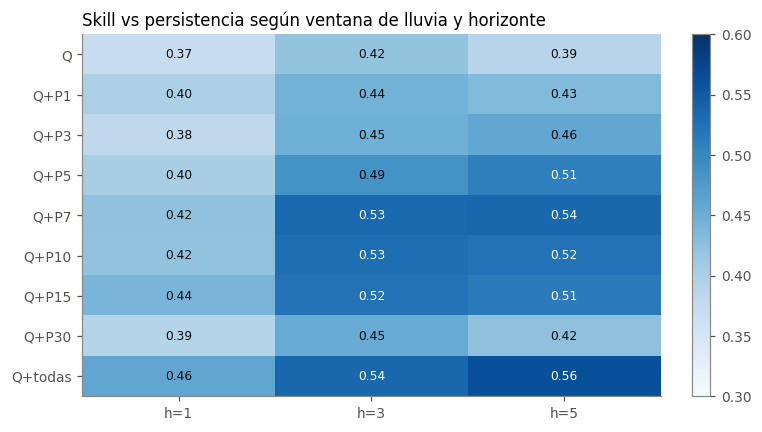

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(tab_skill.values, cmap='Blues', aspect='auto', vmin=0.3, vmax=0.6)
ax.set_xticks(range(len(HORIZ))); ax.set_xticklabels([f'h={h}' for h in HORIZ])
ax.set_yticks(range(len(orden))); ax.set_yticklabels(orden); ax.grid(False)
for i in range(len(orden)):
    for j in range(len(HORIZ)):
        v = tab_skill.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if v > 0.5 else '#0b0b0b')
ax.set_title('Skill vs persistencia según ventana de lluvia y horizonte', loc='left')
plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout(); plt.savefig(f'{FIG}/ablacion_ventanas.png', dpi=150); plt.show()

In [17]:
ganancia = (tab_skill.drop(index='Q') - tab_skill.loc['Q'])
print('Ganancia de skill por agregar lluvia respecto al modelo solo-caudal:')
print(ganancia.round(3))
mejor = ganancia.drop(index='Q+todas').idxmax()
print('\nMejor ventana individual por horizonte:', mejor.to_dict())

Ganancia de skill por agregar lluvia respecto al modelo solo-caudal:
h             1      3      5
conjunto                     
Q+P1      0.028  0.023  0.044
Q+P3      0.010  0.027  0.070
Q+P5      0.031  0.065  0.119
Q+P7      0.050  0.113  0.148
Q+P10     0.049  0.108  0.135
Q+P15     0.068  0.103  0.124
Q+P30     0.019  0.033  0.036
Q+todas   0.088  0.115  0.175

Mejor ventana individual por horizonte: {1: 'Q+P15', 3: 'Q+P7', 5: 'Q+P7'}


## 8. Comparación de modelos

Todos los modelos usan el mismo `Pipeline` (mismo `ColumnTransformer`, mismas variables y mismos pesos para caudales altos) y se evalúan en el mismo test:

- Ridge: regresión lineal regularizada (referencia lineal).
- Random Forest: promedio de árboles entrenados en paralelo.
- XGBoost y LightGBM: gradient boosting (árboles en serie que corrigen el error de los anteriores).

In [18]:
modelos = {
    'Ridge': lambda: Ridge(alpha=1.0),
    'Random Forest': lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    'XGBoost': lambda: XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=2),
    'LightGBM': lgbm}
comp = []
for h in HORIZ:
    _, _, ite = datos_h(h)
    for n, f_ in modelos.items():
        m, _ = evaluar(h, entrenar(h, f_(), ALL_COLS), ite)
        comp.append(dict(h=h, modelo=n, **m))
comp = pd.DataFrame(comp)
tab_comp = comp.pivot(index='modelo', columns='h', values='Skill_pers').loc[list(modelos)]
print('Skill frente a la persistencia (test):'); print(tab_comp.round(3))
comp[comp.h == 3].set_index('modelo').drop(columns='h').round(3)

Skill frente a la persistencia (test):
h                  1      3      5
modelo                            
Ridge          0.402  0.409  0.406
Random Forest  0.407  0.535  0.544
XGBoost        0.458  0.542  0.564
LightGBM       0.460  0.536  0.563


,NSE,KGE,Skill_pers,RMSE,RMSE_alto,PBIAS_alto
modelo,,,,,,
Ridge,0.969,0.981,0.409,59.078,136.177,0.011
Random Forest,0.976,0.981,0.535,52.393,121.648,-2.360
XGBoost,0.976,0.980,0.542,52.016,120.764,-2.580
LightGBM,0.976,0.980,0.536,52.369,123.156,-2.671


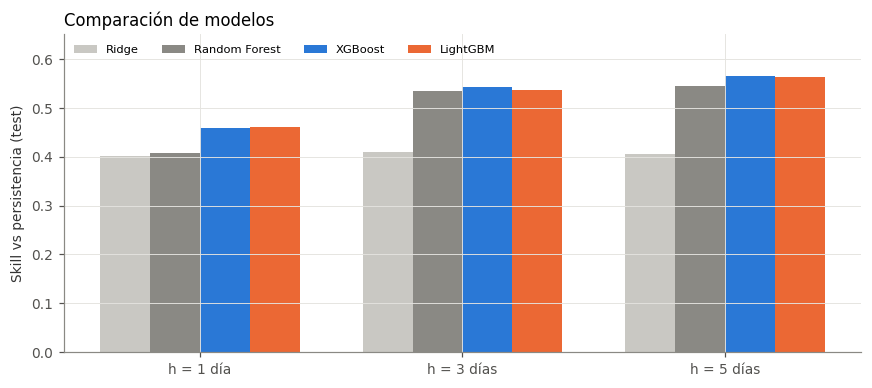

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.6)); wb = 0.19
cols_m = ['#c9c8c3', '#8a8984', '#2a78d6', C_MOD]
for i, (n, c) in enumerate(zip(tab_comp.index, cols_m)):
    ax.bar(np.arange(len(HORIZ)) + (i - 1.5) * wb, tab_comp.loc[n], width=wb, color=c, label=n)
ax.set_xticks(range(len(HORIZ))); ax.set_xticklabels([f'h = {h} día{"s" if h > 1 else ""}' for h in HORIZ])
ax.set_ylim(0, 0.65); ax.set_ylabel('Skill vs persistencia (test)'); ax.legend(fontsize=7.5, ncol=4, loc='upper left')
ax.set_title('Comparación de modelos', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/comparacion_modelos.png', dpi=150); plt.show()

In [20]:
# Efecto de ponderar los caudales altos (LightGBM, h = 3)
_, _, ite = datos_h(3)
pond = pd.DataFrame({f'Peso 3 a Q > Q90: {p}': evaluar(3, entrenar(3, lgbm(), ALL_COLS, p), ite)[0] for p in [False, True]}).T
pond.round(3)

,NSE,KGE,Skill_pers,RMSE,RMSE_alto,PBIAS_alto
Peso 3 a Q > Q90: False,0.976,0.976,0.534,52.447,125.410,-2.958
Peso 3 a Q > Q90: True,0.976,0.980,0.536,52.369,123.156,-2.671


Los modelos de boosting (XGBoost y LightGBM, prácticamente empatados) superan a Ridge y a Random Forest en los tres horizontes. Se adopta LightGBM por su desempeño y menor costo de entrenamiento. Ponderar los caudales altos mejora el KGE y el error en crecidas sin penalizar el desempeño global.

## 9. Optimización de hiperparámetros (LightGBM, validación cruzada temporal)

`RandomizedSearchCV` con `TimeSeriesSplit` (4 bloques, 15 combinaciones) sobre el período de entrenamiento, para h = 3: cada bloque de validación es posterior a su bloque de entrenamiento, sin fuga de información futura.

In [21]:
H = 3
y, itr, ite = datos_h(H)
busqueda = RandomizedSearchCV(
    crear_pipeline(LGBMRegressor(verbose=-1, random_state=SEED, subsample_freq=1, **LGB_DET), ALL_COLS),
    param_distributions={
        'modelo__n_estimators': [200, 400, 600],
        'modelo__learning_rate': [0.01, 0.02, 0.03, 0.05],
        'modelo__num_leaves': [15, 31, 63],
        'modelo__min_child_samples': [10, 20, 30, 50],
        'modelo__subsample': [0.7, 0.8, 0.9],
        'modelo__colsample_bytree': [0.6, 0.8, 1.0],
        'modelo__reg_lambda': [0, 1, 5]},
    n_iter=15, cv=TimeSeriesSplit(n_splits=4), scoring='neg_mean_squared_error', random_state=SEED, n_jobs=1)
busqueda.fit(X.loc[itr, ALL_COLS], y[itr], modelo__sample_weight=pesos_muestra(H, itr))
MEJORES = {k.replace('modelo__', ''): v for k, v in busqueda.best_params_.items()}
mk = lambda **kw: LGBMRegressor(verbose=-1, random_state=SEED, subsample_freq=1, **LGB_DET, **{**MEJORES, **kw})
print('Mejores hiperparámetros:', MEJORES)
m_tuned, _ = evaluar(H, busqueda.best_estimator_, ite)
m_def = comp.query('modelo == "LightGBM" and h == 3').iloc[0][['NSE', 'KGE', 'Skill_pers', 'RMSE', 'RMSE_alto', 'PBIAS_alto']]
pd.DataFrame({'LightGBM por defecto': m_def, 'LightGBM optimizado': pd.Series(m_tuned), 'Persistencia': base.loc[H]}).round(3)

Mejores hiperparámetros: {'subsample': 0.7, 'reg_lambda': 5, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 10, 'learning_rate': 0.02, 'colsample_bytree': 0.6}


,LightGBM por defecto,LightGBM optimizado,Persistencia
KGE,0.979788,0.983,0.974
NSE,0.975724,0.976,0.948
PBIAS_alto,-2.671064,-2.154,NaN
RMSE,52.369258,51.967,76.852
RMSE_alto,123.15552,120.123,172.401
Skill_pers,0.535651,0.543,NaN


## 10. Modelos finales (h = 1, 3 y 5 días)

Un modelo LightGBM optimizado por horizonte, entrenado con todas las variables (caudales recientes y tendencias, P1 a P30, lluvia rezagada, API y mes).

In [22]:
finales, metricas = {}, {}
for h in HORIZ:
    finales[h] = entrenar(h, mk(), ALL_COLS)
    _, _, ite_h = datos_h(h)
    metricas[h], _ = evaluar(h, finales[h], ite_h)
metricas_df = pd.DataFrame(metricas).T
metricas_df.index.name = 'h'
metricas_df = metricas_df.join(base[['NSE', 'RMSE_alto']].rename(columns={'NSE': 'NSE_pers', 'RMSE_alto': 'RMSE_alto_pers'}))
R['metricas_finales'] = metricas_df.round(4).to_dict(orient='index')
metricas_df.round(3)

,NSE,KGE,Skill_pers,RMSE,RMSE_alto,PBIAS_alto,NSE_pers,RMSE_alto_pers
h,,,,,,,,
1,0.996,0.997,0.464,22.257,53.900,-0.459,0.992,69.391
3,0.976,0.983,0.543,51.967,120.123,-2.154,0.948,172.401
5,0.946,0.963,0.559,77.889,172.528,-4.037,0.878,261.917


In [23]:
def serie_pronostico(h, pipe):
    """Observado, modelo y persistencia indexados por la FECHA OBJETIVO (t + h)."""
    _, _, ite_h = datos_h(h)
    idx = ite_h[ite_h].index
    q0 = serie.Q[idx].values
    d = pd.DataFrame({'obs': serie.Q.shift(-h)[idx].values, 'mod': q0 * np.exp(pipe.predict(X.loc[idx])), 'pers': q0},
                     index=idx + pd.Timedelta(days=h))
    return d.asfreq('D')
SP = {h: serie_pronostico(h, finales[h]) for h in HORIZ}
sp = SP[H]

## 11. Evaluación de la serie completa (test 2013–2023)

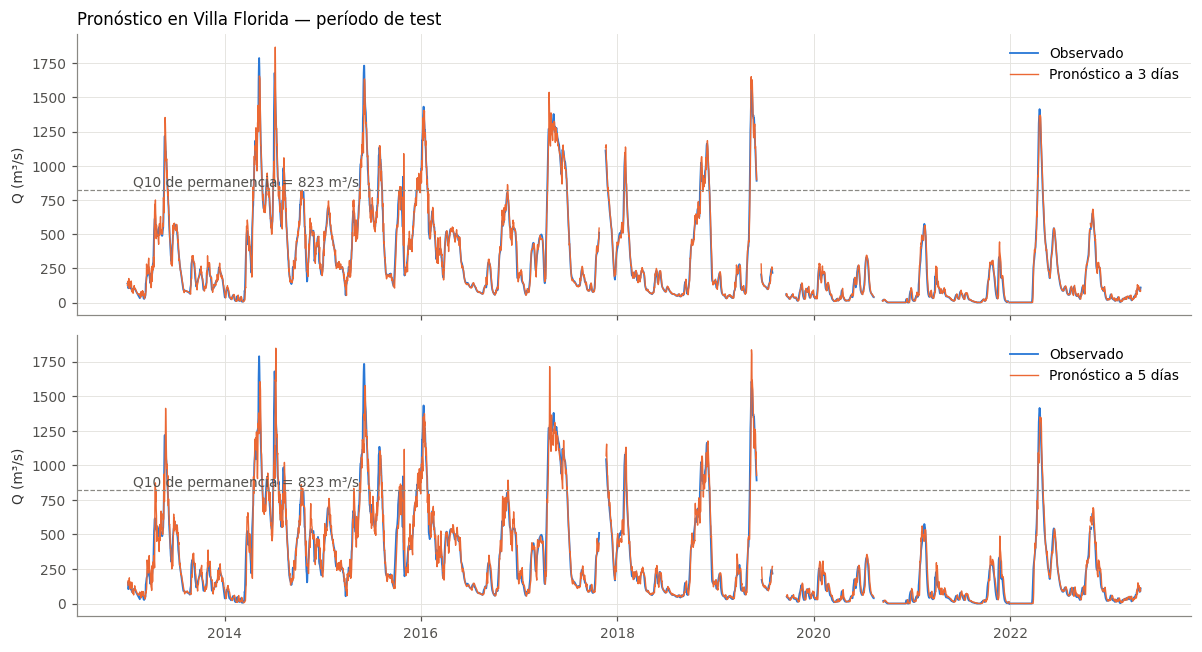

In [24]:
fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, h in zip(axs, [3, 5]):
    ax.plot(SP[h].index, SP[h].obs, color=C_OBS, lw=1.2, label='Observado')
    ax.plot(SP[h].index, SP[h]['mod'], color=C_MOD, lw=0.9, label=f'Pronóstico a {h} días')
    ax.axhline(Q90, color='#8a8984', lw=0.8, ls='--'); ax.text(SP[h].index[20], Q90 * 1.03, f'Q10 de permanencia = {Q90:.0f} m³/s', color='#52514e')
    ax.set_ylabel('Q (m³/s)'); ax.legend(loc='upper right')
axs[0].set_title('Pronóstico en Villa Florida — período de test', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/hidrograma_test.png', dpi=150); plt.show()

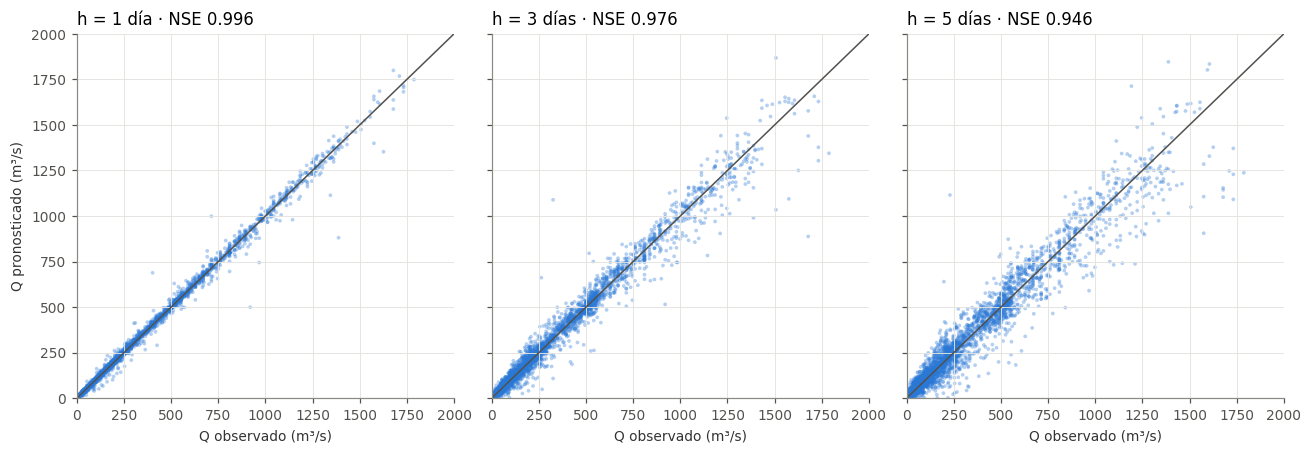

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4.2), sharex=True, sharey=True)
for ax, h in zip(axs, HORIZ):
    d = SP[h].dropna()
    ax.scatter(d.obs, d['mod'], s=6, color=C_OBS, alpha=0.35, edgecolors='none')
    lim = [0, 2000]
    ax.plot(lim, lim, color='#52514e', lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f'h = {h} día{"s" if h > 1 else ""} · NSE {metricas[h]["NSE"]:.3f}', loc='left')
    ax.set_xlabel('Q observado (m³/s)')
axs[0].set_ylabel('Q pronosticado (m³/s)')
plt.tight_layout(); plt.savefig(f'{FIG}/dispersion.png', dpi=150); plt.show()

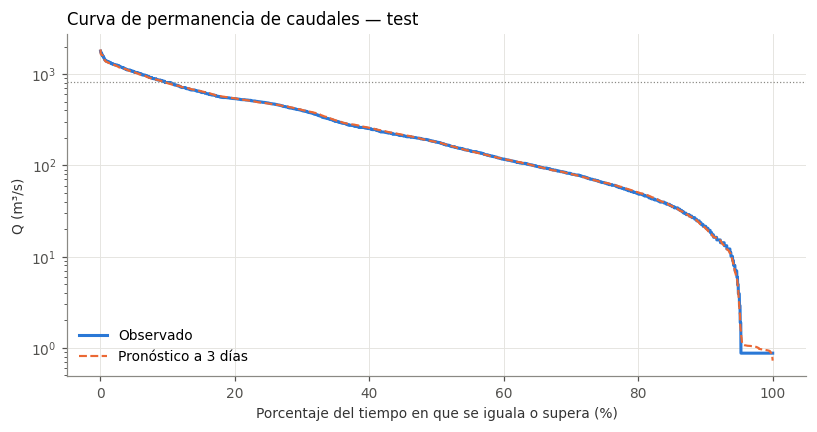

In [26]:
d = sp.dropna()
exc = np.arange(1, len(d) + 1) / (len(d) + 1) * 100
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(exc, np.sort(d.obs.values)[::-1], color=C_OBS, lw=2, label='Observado')
ax.plot(exc, np.sort(d['mod'].values)[::-1], color=C_MOD, lw=1.4, ls='--', label=f'Pronóstico a {H} días')
ax.set_yscale('log'); ax.set_xlabel('Porcentaje del tiempo en que se iguala o supera (%)'); ax.set_ylabel('Q (m³/s)')
ax.axhline(Q90, color='#8a8984', lw=0.8, ls=':')
ax.legend(); ax.set_title('Curva de permanencia de caudales — test', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/curva_permanencia.png', dpi=150); plt.show()

## 12. Alcance del pronóstico: dónde es confiable y por qué se excluyen los estiajes

Se calcula el error relativo por tramo de la curva de permanencia (entrenamiento) y por estado del río, para cada horizonte.

In [27]:
q_tr = serie.Q[TRAIN].dropna()
PERM = {p: float(q_tr.quantile(1 - p / 100)) for p in [2, 5, 10, 25, 50, 75]}
cortes = [0, PERM[75], PERM[50], PERM[25], PERM[10], PERM[5], PERM[2], np.inf]
etq = ['< 112 (superado > 75 % del tiempo)', '112–263 (50–75 %)', '263–500 (25–50 %)', '500–823 (10–25 %)', '823–993 (5–10 %)', '993–1 180 (2–5 %)', '> 1 180 (< 2 %)']
etq = [e.replace('112', f'{PERM[75]:.0f}').replace('263', f'{PERM[50]:.0f}').replace('500', f'{PERM[25]:.0f}').replace('823', f'{PERM[10]:.0f}').replace('993', f'{PERM[5]:.0f}') for e in etq]
def resumen_err(g):
    return pd.Series({'dias': len(g), 'error_tipico_pct': 100 * g.err.abs().median(), 'dentro_20pct': 100 * (g.err.abs() <= 0.20).mean(),
                      'sesgo_pct': 100 * (g['mod'].sum() - g.obs.sum()) / g.obs.sum()})
VAL = {}
for h in HORIZ:
    dv = SP[h].dropna().copy(); dv['err'] = (dv['mod'] - dv.obs) / dv.obs
    dv['tramo'] = pd.cut(dv.obs, cortes, labels=etq)
    VAL[h] = dv.groupby('tramo', observed=True).apply(resumen_err).iloc[::-1]
val_perm = pd.concat({f'h={h}': VAL[h][['error_tipico_pct', 'dentro_20pct']] for h in HORIZ}, axis=1)
val_perm.insert(0, 'dias', VAL[3]['dias'])
dv = SP[H].dropna().copy(); dv['err'] = (dv['mod'] - dv.obs) / dv.obs; dv['subiendo'] = dv.obs / dv.pers > 1.10
val_estado = pd.DataFrame({'Río estable o bajando': resumen_err(dv[~dv.subiendo]), 'Río subiendo (> 10 % en 3 días)': resumen_err(dv[dv.subiendo]),
                           'Caudal alto (> Q10 perm.) y subiendo': resumen_err(dv[dv.subiendo & (dv.obs > Q90)]),
                           'Caudal alto (> Q10 perm.) sin subida': resumen_err(dv[~dv.subiendo & (dv.obs > Q90)])}).T
display(val_perm.round(1)); display(val_estado.round(1))

dias              h=1                           h=3                           h=5             
                                           error_tipico_pct dentro_20pct error_tipico_pct dentro_20pct error_tipico_pct dentro_20pct
tramo                                                                                                                               
> 1 180 (< 2 %)                      120.0              1.8         99.2              6.0         90.8             10.0         77.5
993–1 180 (2–5 %)                    104.0              1.2        100.0              3.7         97.1              6.7         87.3
823–993 (5–10 %)                     124.0              2.0         98.4              4.4         94.4              8.7         90.3
500–823 (10–25 %)                    505.0              1.4         99.6              4.9         96.4              9.0         85.9
263–500 (25–50 %)                    548.0              1.7         98.9              5.7         89.1             11.7         73.4
112–263 (50–75 %)                    828.0              2.6         96.9              9.2         76.2             16.2         57.8
< 112 (superado > 75 % del tiempo)  1415.0              4.5         90.6             15.5         58.9             25.1         42.0

,dias,error_tipico_pct,dentro_20pct,sesgo_pct
Río estable o bajando,2597.0,7.1,79.6,3.9
Río subiendo (> 10 % en 3 días),1047.0,12.5,66.7,-9.6
Caudal alto (> Q10 perm.) y subiendo,86.0,11.9,77.9,-12.3
Caudal alto (> Q10 perm.) sin subida,262.0,3.7,99.2,1.4


Cambio diario relativo |Δlog Q|: mediana 0.035 en estiaje frente a 0.039 en caudales medios y altos
Caudal mínimo anual de 7 días: tendencia de Sen -1.28 m³/s/año (Kendall p = 0.015)


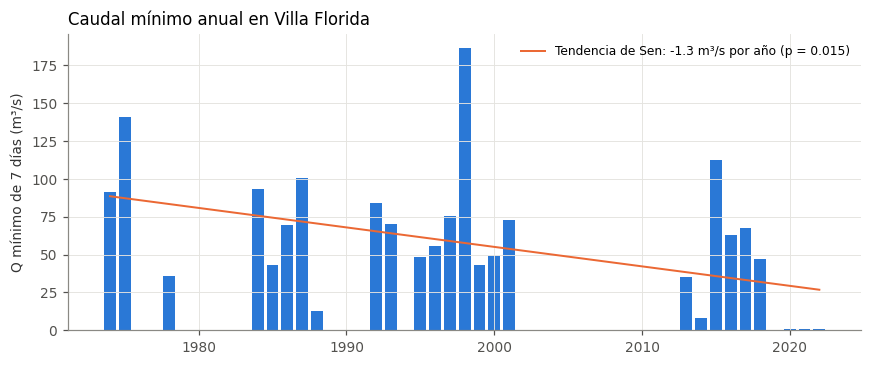

,dias,NSE,KGE,Skill_pers,RMSE_alto
h,,,,,
1,2235,0.993,0.994,0.466,53.900
3,2229,0.964,0.970,0.551,120.123
5,2223,0.922,0.940,0.572,172.528


In [28]:
# Variabilidad de los estiajes y desempeño dentro del alcance (Q(t) >= caudal de 75 % de permanencia)
lq = np.log(serie.Q)
var_rel = pd.DataFrame({'Estiaje (< Q75 perm.)': lq.diff()[serie.Q.shift(1) < PERM[75]].abs().describe(percentiles=[0.5, 0.9]),
                        'Medios y altos (>= Q75 perm.)': lq.diff()[serie.Q.shift(1) >= PERM[75]].abs().describe(percentiles=[0.5, 0.9])}).T
from scipy import stats
qmin7 = serie.Q.rolling(7).mean().resample('YE').min()[serie.Q.resample('YE').count() > 330]
kt = stats.kendalltau(qmin7.index.year, qmin7.values); sen = stats.theilslopes(qmin7.values, qmin7.index.year)[0]
print(f'Cambio diario relativo |Δlog Q|: mediana {var_rel.loc["Estiaje (< Q75 perm.)", "50%"]:.3f} en estiaje frente a {var_rel.loc["Medios y altos (>= Q75 perm.)", "50%"]:.3f} en caudales medios y altos')
print(f'Caudal mínimo anual de 7 días: tendencia de Sen {sen:.2f} m³/s/año (Kendall p = {kt.pvalue:.3f})')
filas = []
for h in HORIZ:
    _, _, ite_h = datos_h(h)
    dom = ite_h & (serie.Q >= PERM[75])
    m_dom, _ = evaluar(h, finales[h], dom)
    filas.append(dict(h=h, dias=int(dom.sum()), **{k: m_dom[k] for k in ['NSE', 'KGE', 'Skill_pers', 'RMSE_alto']}))
dominio = pd.DataFrame(filas).set_index('h')
R['alcance'] = {'umbrales_permanencia': PERM, 'max_test': float(sp.obs.max()), 'error_por_tramo': {str(h): VAL[h].reset_index().round(2).to_dict(orient='records') for h in HORIZ},
                'estado_h3': val_estado.round(2).to_dict(orient='index'), 'variabilidad': var_rel.round(4).to_dict(orient='index'),
                'qmin7_sen': float(sen), 'qmin7_p': float(kt.pvalue), 'metricas_dominio': dominio.round(4).to_dict(orient='index')}
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(qmin7.index.year, qmin7.values, color=C_OBS, width=0.8)
x0 = qmin7.index.year.values; ax.plot(x0, np.median(qmin7.values - sen * x0) + sen * x0, color=C_MOD, lw=1.3, label=f'Tendencia de Sen: {sen:.1f} m³/s por año (p = {kt.pvalue:.3f})')
ax.set_ylabel('Q mínimo de 7 días (m³/s)'); ax.legend(fontsize=8); ax.set_title('Caudal mínimo anual en Villa Florida', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/estiaje_minimos.png', dpi=150); plt.show()
dominio.round(3)

El error relativo crece al bajar el caudal: por debajo del caudal de 75 % de permanencia supera el 15 %, los cambios diarios relativos son más bruscos y el caudal mínimo anual muestra una tendencia descendente significativa que no se explica por la lluvia (posibles extracciones, cambios en la curva altura–caudal en aguas bajas). Por eso el pronóstico se limita a caudales medios y altos: la aplicación no emite pronóstico cuando el caudal del día es menor que el de 75 % de permanencia.

## 13. Análisis de extremos y desfase

Picos observados mayores al caudal de 10 % de permanencia, separados al menos 20 días. Para cada uno: pico observado, valor pronosticado para ese día (emitido 3 días antes), máximo pronosticado en ±5 días y desfase.

In [29]:
from scipy.signal import find_peaks
o = sp.obs.interpolate(limit=3)
picos, _ = find_peaks(o.fillna(0).values, height=Q90, distance=20)
ev = []
for i in picos:
    t = o.index[i]
    win = sp.loc[t - pd.Timedelta(days=5): t + pd.Timedelta(days=5)]
    ev.append(dict(fecha=t.date(), Q_obs=sp.obs[t], Q_mod_mismo_dia=sp['mod'][t], Q_pers_mismo_dia=sp.pers[t],
                   Q_mod_max_5d=win['mod'].max(), desfase_mod_dias=(win['mod'].idxmax() - t).days,
                   desfase_pers_dias=(win.pers.idxmax() - t).days))
eventos = pd.DataFrame(ev)
eventos['error_pico_mod_pct'] = 100 * (eventos.Q_mod_mismo_dia - eventos.Q_obs) / eventos.Q_obs
eventos['error_pico_pers_pct'] = 100 * (eventos.Q_pers_mismo_dia - eventos.Q_obs) / eventos.Q_obs
R['eventos'] = eventos.assign(fecha=eventos.fecha.astype(str)).round(2).to_dict(orient='records')
eventos.round(1)

,fecha,Q_obs,Q_mod_mismo_dia,Q_pers_mismo_dia,Q_mod_max_5d,desfase_mod_dias,desfase_pers_dias,error_pico_mod_pct,error_pico_pers_pct
0,2013-05-23,1218.9,1058.9,899.3,1353.5,1,3,-13.1,-26.2
1,2014-05-09,1788.1,1344.6,1344.6,1657.2,1,3,-24.8,-24.8
2,2014-06-06,902.2,890.9,805.0,947.0,2,3,-1.3,-10.8
3,2014-07-05,1678.3,888.0,874.1,1868.0,3,3,-47.1,-47.9
4,2014-08-08,985.8,745.1,746.1,1058.5,1,3,-24.4,-24.3
5,2015-06-03,1732.3,1377.5,1387.9,1635.9,2,3,-20.5,-19.9
6,2015-07-30,1133.3,990.4,949.1,1147.0,1,3,-12.6,-16.3
7,2015-10-26,919.5,515.1,669.9,1089.1,3,3,-44.0,-27.1
8,2015-12-21,890.8,914.0,852.2,944.9,3,3,2.6,-4.3
9,2016-01-11,1432.5,1283.9,1270.1,1405.5,1,3,-10.4,-11.3


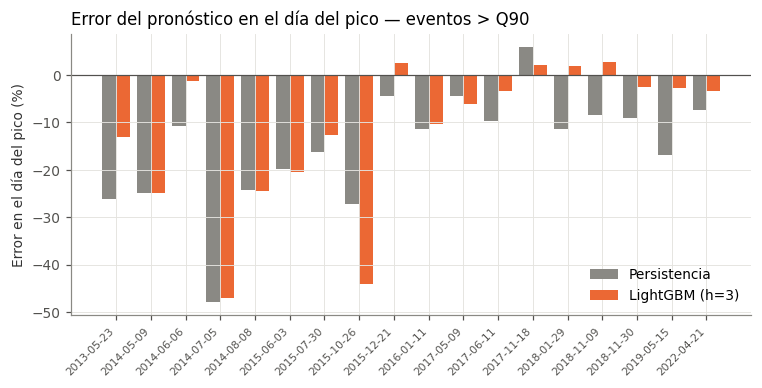

In [30]:
fig, ax = plt.subplots(figsize=(7, 3.6))
xx = np.arange(len(eventos))
ax.bar(xx - 0.2, eventos.error_pico_pers_pct, width=0.4, color=C_PERS, label='Persistencia')
ax.bar(xx + 0.2, eventos.error_pico_mod_pct, width=0.4, color=C_MOD, label=f'LightGBM (h={H})')
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_xticks(xx); ax.set_xticklabels([str(f) for f in eventos.fecha], rotation=45, ha='right', fontsize=7)
ax.set_ylabel('Error en el día del pico (%)'); ax.legend()
ax.set_title('Error del pronóstico en el día del pico — eventos > Q90', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/error_picos.png', dpi=150); plt.show()

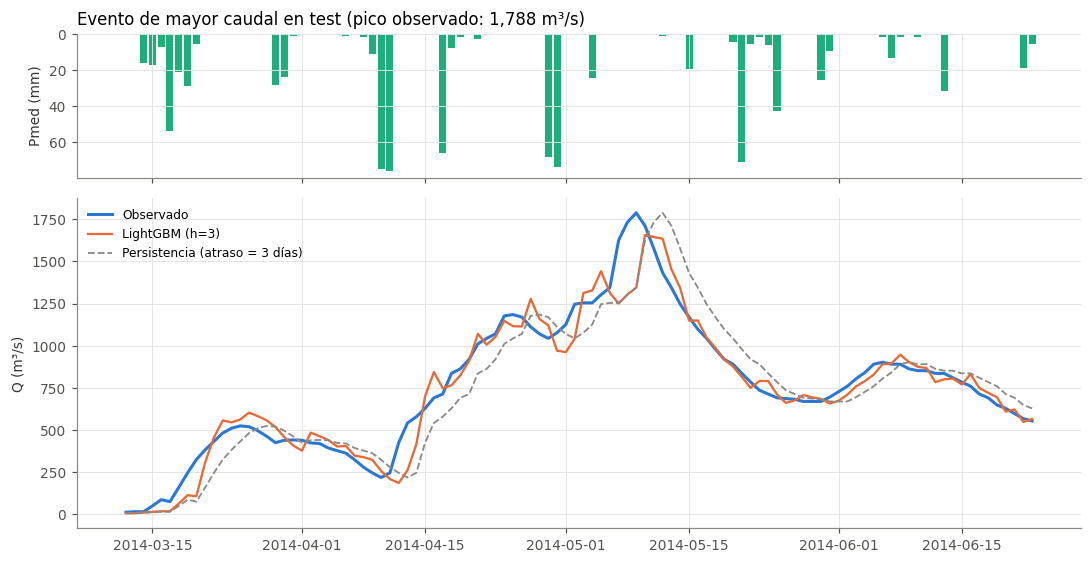

In [31]:
t_pico = sp.obs.idxmax()   # fecha del pico observado máximo del test
ventana = slice(t_pico - pd.Timedelta(days=58), t_pico + pd.Timedelta(days=45))
def grafico_evento(ventana, extra=None, fn='evento_pico.png', titulo=None):
    fig, axs = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw={'height_ratios': [1, 2.3]})
    pe = serie.Pmed[ventana]
    axs[0].bar(pe.index, pe.values, color=C_P, width=0.8); axs[0].invert_yaxis(); axs[0].set_ylabel('Pmed (mm)')
    e = sp[ventana]
    if extra is not None: extra(axs[1])
    axs[1].plot(e.index, e.obs, color=C_OBS, lw=2, label='Observado')
    axs[1].plot(e.index, e['mod'], color=C_MOD, lw=1.5, label=f'LightGBM (h={H})')
    axs[1].plot(e.index, e.pers, color=C_PERS, lw=1.2, ls='--', label='Persistencia (atraso = 3 días)')
    axs[1].set_ylabel('Q (m³/s)'); axs[1].legend(loc='upper left', fontsize=8)
    axs[0].set_title(titulo or f'Evento de mayor caudal en test (pico observado: {e.obs.max():,.0f} m³/s)', loc='left')
    plt.tight_layout(); plt.savefig(f'{FIG}/{fn}', dpi=150); plt.show()
grafico_evento(ventana)

### Desfase temporal (error de fase)

En los hidrogramas el pronóstico aparece desplazado hacia la derecha: las subidas llegan tarde. Para medirlo, la serie pronosticada se desplaza L días y se busca el L que maximiza el NSE contra la observada. La persistencia a h días tiene, por definición, un atraso de h días.

Atraso que maximiza el NSE (días):
LightGBM h=1        1
LightGBM h=3        1
LightGBM h=5        3
Persistencia h=3    3
dtype: int64


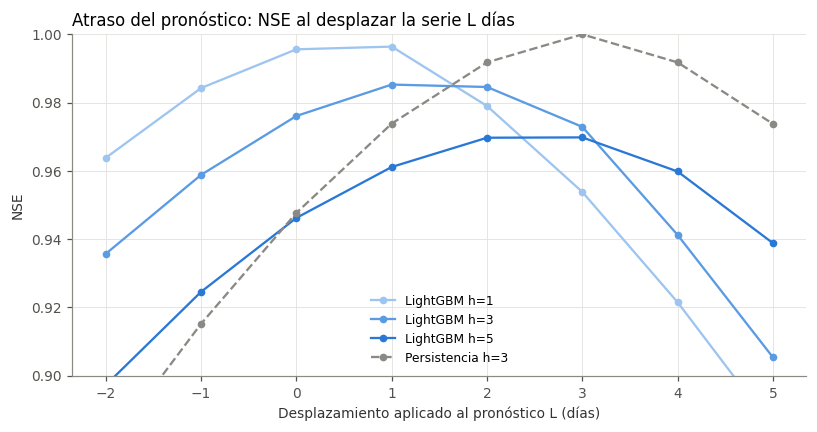

In [32]:
def curva_desfase(o, s, Ls=range(-2, 6)):
    res = {}
    for L in Ls:
        b = s.shift(-L); m = o.notna() & b.notna()
        res[L] = nse(o[m].values, b[m].values)
    return pd.Series(res)
cd = pd.DataFrame({f'LightGBM h={h}': curva_desfase(SP[h].obs, SP[h]['mod']) for h in HORIZ})
cd['Persistencia h=3'] = curva_desfase(sp.obs, sp.pers)
atraso = cd.idxmax()
R['desfase'] = {k: int(v) for k, v in atraso.items()}
print('Atraso que maximiza el NSE (días):'); print(atraso)
fig, ax = plt.subplots(figsize=(7.5, 4))
for col, c, ls in zip(cd.columns, ['#9ec5f0', '#5a9be3', C_OBS, C_PERS], ['-', '-', '-', '--']):
    ax.plot(cd.index, cd[col], marker='o', ms=4, color=c, ls=ls, label=col)
ax.set_xlabel('Desplazamiento aplicado al pronóstico L (días)'); ax.set_ylabel('NSE')
ax.set_ylim(0.9, 1.0); ax.legend(fontsize=8)
ax.set_title('Atraso del pronóstico: NSE al desplazar la serie L días', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/desfase.png', dpi=150); plt.show()

El pronóstico reconoce todas las crecidas, pero en la subida llega con un atraso de ~1 día (la persistencia, h días). En análisis complementarios se probó reducirlo con lluvia por zonas, mayor peso a las subidas, lluvia futura (perfecta y del pronóstico meteorológico GFS), la estación aguas arriba Yuty y lluvia satelital CHIRPS: todas mejoran algo la magnitud y ninguna elimina el atraso, que se debe a los afluentes sin medición (Tebicuary-mí, Pirapó). Para la alerta el atraso pesa poco (sección 15).

## 14. Intervalos de confianza

Regresión cuantílica: dos modelos LightGBM estiman los percentiles 5 y 95 del cambio de caudal y forman la banda del 90 %. Como el período de test es más variable que el de entrenamiento, la banda se recalibra con los errores de 2013–2015 (recalibración conformal: se ensancha lo justo para cubrir el 90 % en ese período) y se evalúa en 2016–2023, años no usados en el ajuste ni en la recalibración. También se estima el percentil 75, usado como valor conservador en las subidas.

In [33]:
CUANT, filas = {}, []
for h in HORIZ:
    y_h, itr_h, ite_h = datos_h(h)
    qm = {a: crear_pipeline(mk(objective='quantile', alpha=a), ALL_COLS).fit(X.loc[itr_h, ALL_COLS], y_h[itr_h]) for a in [0.05, 0.75, 0.95]}
    ical = ite_h & (serie.index.year <= 2015); iev = ite_h & (serie.index.year >= 2016)
    yc = y_h[ical].values
    E = np.maximum(qm[0.05].predict(X.loc[ical, ALL_COLS]) - yc, yc - qm[0.95].predict(X.loc[ical, ALL_COLS]))
    qhat = float(np.quantile(E, min(1, np.ceil((len(E) + 1) * 0.9) / len(E))))
    CUANT[h] = {'p05': qm[0.05], 'p95': qm[0.95], 'p75': qm[0.75], 'qhat': qhat}
    qo_, q0_ = serie.Q.shift(-h)[iev].values, serie.Q[iev].values; alto = qo_ > Q90
    for recal in [False, True]:
        qh = qhat if recal else 0.0
        lo = q0_ * np.exp(qm[0.05].predict(X.loc[iev, ALL_COLS]) - qh); hi = q0_ * np.exp(qm[0.95].predict(X.loc[iev, ALL_COLS]) + qh)
        cov = (qo_ >= lo) & (qo_ <= hi)
        filas.append(dict(h=h, recalibrada=recal, cobertura=cov.mean(), cobertura_altos=cov[alto].mean(), ancho_medio=(hi - lo).mean(),
                          ancho_rel_medio=np.mean((hi - lo) / q0_), ancho_medio_altos=(hi - lo)[alto].mean()))
cobertura = pd.DataFrame(filas)
R['cobertura'] = cobertura.round(4).to_dict(orient='records'); R['qhat'] = {h: CUANT[h]['qhat'] for h in HORIZ}
cobertura.round(3)

,h,recalibrada,cobertura,cobertura_altos,ancho_medio,ancho_rel_medio,ancho_medio_altos
0,1,False,0.825,0.939,30.670,0.165,108.733
1,1,True,0.902,0.995,46.761,0.229,180.382
2,3,False,0.765,0.892,89.142,0.478,301.279
3,3,True,0.878,0.985,140.663,0.693,526.993
4,5,False,0.764,0.837,145.394,0.824,442.090
5,5,True,0.857,0.963,221.397,1.163,760.244


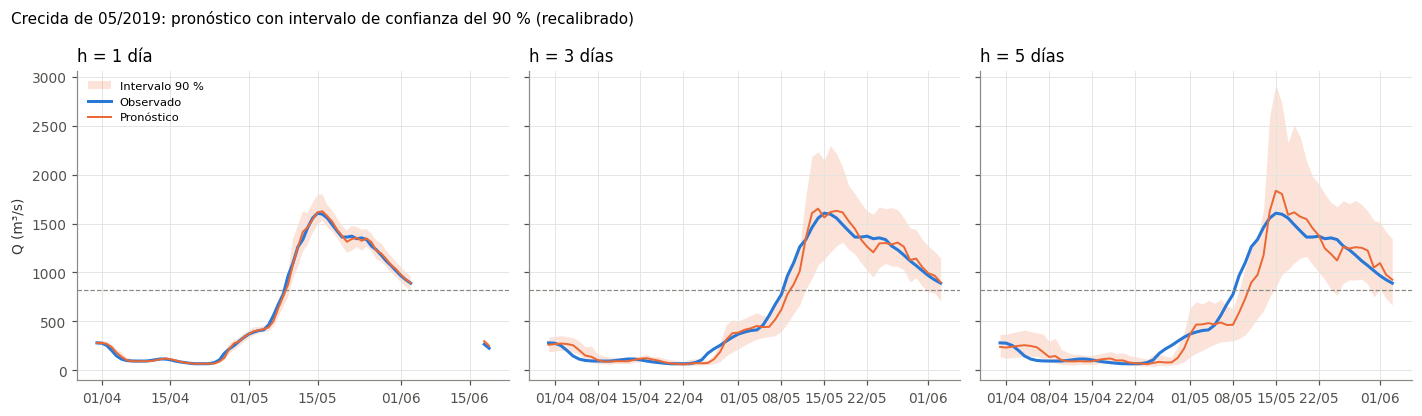

In [34]:
def bandas(h, idx):
    q0_ = serie.Q[idx].values; Xb = X.loc[idx, ALL_COLS]; c = CUANT[h]
    return pd.DataFrame({'obs': serie.Q.shift(-h)[idx].values, 'mod': q0_ * np.exp(finales[h].predict(Xb)),
                         'lo': q0_ * np.exp(c['p05'].predict(Xb) - c['qhat']), 'hi': q0_ * np.exp(c['p95'].predict(Xb) + c['qhat'])},
                        index=idx + pd.Timedelta(days=h)).asfreq('D')
ev_eval = SP[3][SP[3].index.year >= 2016].obs.idxmax()
v2 = slice(ev_eval - pd.Timedelta(days=45), ev_eval + pd.Timedelta(days=35))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, h in zip(axs, HORIZ):
    b = bandas(h, datos_h(h)[2][datos_h(h)[2]].index)[v2]
    ax.fill_between(b.index, b.lo, b.hi, color=C_MOD, alpha=0.18, lw=0, label='Intervalo 90 %')
    ax.plot(b.index, b.obs, color=C_OBS, lw=2, label='Observado'); ax.plot(b.index, b['mod'], color=C_MOD, lw=1.3, label='Pronóstico')
    ax.axhline(Q90, color='#8a8984', lw=0.8, ls='--'); ax.set_title(f'h = {h} día{"s" if h > 1 else ""}', loc='left')
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d/%m'))
axs[0].set_ylabel('Q (m³/s)'); axs[0].legend(fontsize=7.5, loc='upper left')
plt.suptitle(f'Crecida de {ev_eval:%m/%Y}: pronóstico con intervalo de confianza del 90 % (recalibrado)', x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.savefig(f'{FIG}/intervalos_evento.png', dpi=150); plt.show()

## 15. Alerta de crecidas: ¿se superará el caudal de 10 % de permanencia?

Para alertar no hace falta acertar el caudal de un día exacto: alcanza con saber si el caudal superará el umbral (Q10 de permanencia = 823 m³/s) en los próximos 3 o 5 días. Se comparan, solo en días con el río por debajo del umbral:

- Regresión, valor central: alguno de los pronósticos dentro de la ventana supera el umbral.
- Regresión, percentil 75: ídem con el percentil 75.
- Clasificador: LightGBM (mismo Pipeline y variables) que estima la probabilidad de superar el umbral en la ventana. El valor de corte de probabilidad se elige con predicciones fuera de muestra dentro del entrenamiento (`TimeSeriesSplit`), sin mirar el test.
- Persistencia de la tendencia: extrapolar la subida del último día (regla simple de referencia).

Evaluación por evento: cada cruce ascendente del umbral en 2013–2023 (con al menos 5 días previos por debajo) es una crecida; se registra si hubo alerta en los días previos (dentro de la ventana) y con cuánta anticipación. Una falsa alarma es un episodio de alerta sin superación en la ventana siguiente.

In [35]:
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
U = Q90
PC = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8, subsample_freq=1,
          colsample_bytree=0.7, reg_lambda=5, verbose=-1, random_state=SEED, **LGB_DET)
def contingencia(o, a):
    h_ = (a & (o == 1)).sum(); fa = (a & (o == 0)).sum(); mi = ((~a) & (o == 1)).sum()
    return dict(POD=h_ / max(h_ + mi, 1), FAR=fa / max(h_ + fa, 1), CSI=h_ / max(h_ + fa + mi, 1))
def max_futuro(w): return pd.concat([serie.Q.shift(-k) for k in range(1, w + 1)], axis=1).max(1, skipna=False)
okx = X['lQ_0'].notna()
REG_C = pd.DataFrame({h: serie.Q * np.exp(finales[h].predict(X[ALL_COLS])) for h in HORIZ}).where(okx)
REG_75 = pd.DataFrame({h: serie.Q * np.exp(CUANT[h]['p75'].predict(X[ALL_COLS])) for h in HORIZ}).where(okx)
VENT_AL = [3, 5]
CLASIF, PROB_AL, filas_dia = {}, {}, []
for w in VENT_AL:
    fm = max_futuro(w); ev = (fm > U).astype(float).where(fm.notna())
    ok = ev.notna() & okx & (serie.Q <= U); itr_, ite_ = ok & TRAIN, ok & TEST
    oof = pd.Series(np.nan, index=serie.index); it = np.where(itr_)[0]
    for a, b in TimeSeriesSplit(5).split(it):
        m_ = crear_pipeline(LGBMClassifier(**PC), ALL_COLS).fit(X.iloc[it[a]][ALL_COLS], ev.iloc[it[a]])
        oof.iloc[it[b]] = m_.predict_proba(X.iloc[it[b]][ALL_COLS])[:, 1]
    mo = oof.notna(); us = np.round(np.arange(0.1, 0.81, 0.05), 2)
    u = float(us[np.argmax([contingencia(ev[mo].values, oof[mo].values >= x)['CSI'] for x in us])])
    clf = crear_pipeline(LGBMClassifier(**PC), ALL_COLS).fit(X.loc[itr_, ALL_COLS], ev[itr_])
    pr = pd.Series(clf.predict_proba(X.loc[okx, ALL_COLS])[:, 1], index=serie.index[okx]).reindex(serie.index)
    CLASIF[w] = {'modelo': clf, 'umbral_prob': u}; PROB_AL[w] = pr
    o = ev[ite_].values; clim = ev[itr_].mean(); hs = [h for h in HORIZ if h <= w]
    r = dict(ventana=w, dias=int(len(o)), dias_con_superacion=int(o.sum()), AUC=roc_auc_score(o, pr[ite_]),
             BSS=1 - brier_score_loss(o, pr[ite_]) / np.mean((o - clim) ** 2), umbral_prob=u)
    for nom, a in [('Clasificador', pr[ite_].values >= u), ('Regresión central', (REG_C.loc[ite_, hs].max(1) > U).values),
                   ('Regresión P75', (REG_75.loc[ite_, hs].max(1) > U).values)]:
        r.update({f'{nom} {k}': v for k, v in contingencia(o, a).items()})
    filas_dia.append(r)
T_DIA = pd.DataFrame(filas_dia).set_index('ventana')
T_DIA.round(3)

,dias,dias_con_superacion,AUC,BSS,umbral_prob,Clasificador POD,Clasificador FAR,Clasificador CSI,Regresión central POD,Regresión central FAR,Regresión central CSI,Regresión P75 POD,Regresión P75 FAR,Regresión P75 CSI
ventana,,,,,,,,,,,,,,
3,3293,42,0.990,0.571,0.3,0.738,0.295,0.564,0.571,0.250,0.480,0.619,0.381,0.448
5,3281,70,0.982,0.477,0.1,0.814,0.584,0.380,0.486,0.261,0.415,0.614,0.377,0.448


In [36]:
def eventos_cruce(U):
    c = serie.Q[(serie.Q > U) & (serie.Q.shift(1) <= U) & TEST]
    return [t for t in c.index if (serie.Q[t - pd.Timedelta(days=5):t - pd.Timedelta(days=1)] <= U).all()]
def evaluar_alerta(alarma, U, W):
    evs = eventos_cruce(U); ant = []
    for c in evs:
        a = [c - pd.Timedelta(days=k) for k in range(W, 0, -1) if alarma.get(c - pd.Timedelta(days=k), False)]
        ant.append((c - a[0]).days if a else 0)
    dias_al = alarma[alarma].index; falsos = n_ep = 0
    if len(dias_al):
        grupo = (pd.Series(dias_al).diff().dt.days != 1).cumsum().values
        for _, g in pd.Series(dias_al).groupby(grupo):
            n_ep += 1
            falsos += int(not (serie.Q[g.iloc[0] + pd.Timedelta(days=1): g.iloc[-1] + pd.Timedelta(days=W)] > U).any())
    anos = TEST.sum() / 365.25
    return dict(eventos=len(evs), detectados=int((np.array(ant) > 0).sum()), anticipacion_media=float(np.mean([a for a in ant if a > 0])),
                episodios=n_ep, falsas_alarmas=falsos, falsas_por_ano=falsos / anos, anticipacion=ant, fechas=[str(e.date()) for e in evs])
filas_ev = []
base_ok = TEST & okx & (serie.Q <= U)
for w in VENT_AL:
    hs = [h for h in HORIZ if h <= w]
    alarmas = {'Regresión (valor central)': (REG_C[hs].max(1) > U) & base_ok, 'Regresión (percentil 75)': (REG_75[hs].max(1) > U) & base_ok,
               'Clasificador (probabilidad)': (PROB_AL[w] >= CLASIF[w]['umbral_prob']) & base_ok,
               'Persistencia de la tendencia': (serie.Q * (serie.Q / serie.Q.shift(1)).clip(lower=1) ** w > U) & base_ok}
    for nom, a in alarmas.items():
        filas_ev.append(dict(ventana=w, metodo=nom, **evaluar_alerta(a, U, w)))
T_EV = pd.DataFrame(filas_ev)
R['alerta'] = {'umbral': float(U), 'umbral_prob': {w: CLASIF[w]['umbral_prob'] for w in VENT_AL},
               'por_dia': T_DIA.round(4).reset_index().to_dict(orient='records'), 'por_evento': T_EV.round(3).to_dict(orient='records')}
T_EV.drop(columns=['anticipacion', 'fechas']).round(2)

,ventana,metodo,eventos,detectados,anticipacion_media,episodios,falsas_alarmas,falsas_por_ano
0,3,Regresión (valor central),14,13,2.08,18,5,0.47
1,3,Regresión (percentil 75),14,13,2.15,22,9,0.85
2,3,Clasificador (probabilidad),14,13,2.54,25,10,0.94
3,3,Persistencia de la tendencia,14,13,2.31,40,27,2.54
4,5,Regresión (valor central),14,13,3.08,25,9,0.85
5,5,Regresión (percentil 75),14,13,3.77,30,14,1.32
6,5,Clasificador (probabilidad),14,13,4.62,42,27,2.54
7,5,Persistencia de la tendencia,14,13,3.77,65,48,4.51


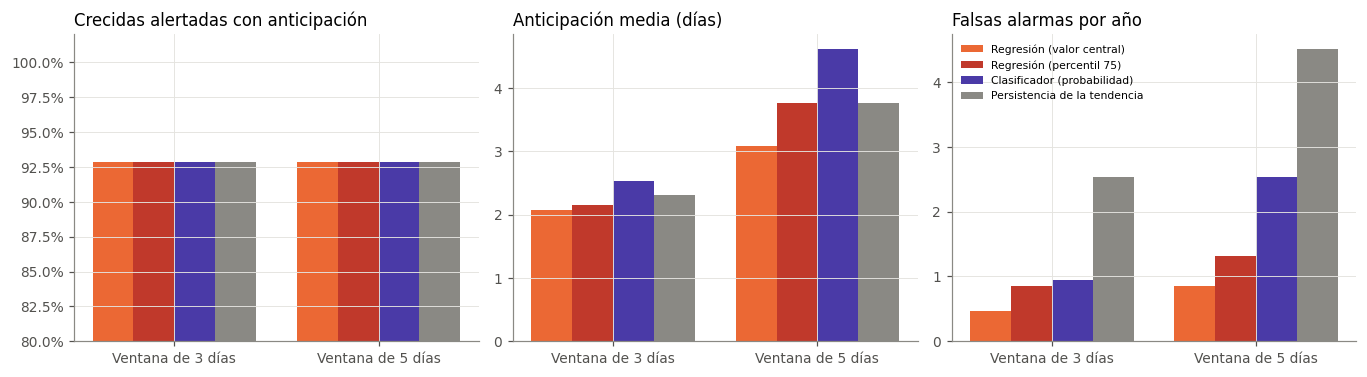

In [37]:
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.5))
met_cols = {'Regresión (valor central)': C_MOD, 'Regresión (percentil 75)': '#c0392b', 'Clasificador (probabilidad)': '#4a3aa7', 'Persistencia de la tendencia': C_PERS}
for ax, (col, tit) in zip(axs, [('detectados', 'Crecidas alertadas con anticipación'), ('anticipacion_media', 'Anticipación media (días)'), ('falsas_por_ano', 'Falsas alarmas por año')]):
    for i, (m, c) in enumerate(met_cols.items()):
        d_ = T_EV[T_EV.metodo == m]
        vals = d_[col] / d_.eventos if col == 'detectados' else d_[col]
        ax.bar(np.arange(len(VENT_AL)) + (i - 1.5) * 0.2, vals, width=0.2, color=c, label=m)
    ax.set_xticks(range(len(VENT_AL))); ax.set_xticklabels([f'Ventana de {w} días' for w in VENT_AL]); ax.set_title(tit, loc='left')
axs[0].set_ylim(0.8, 1.02); axs[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axs[2].legend(fontsize=7, loc='upper left')
plt.tight_layout(); plt.savefig(f'{FIG}/alerta_eventos.png', dpi=150); plt.show()

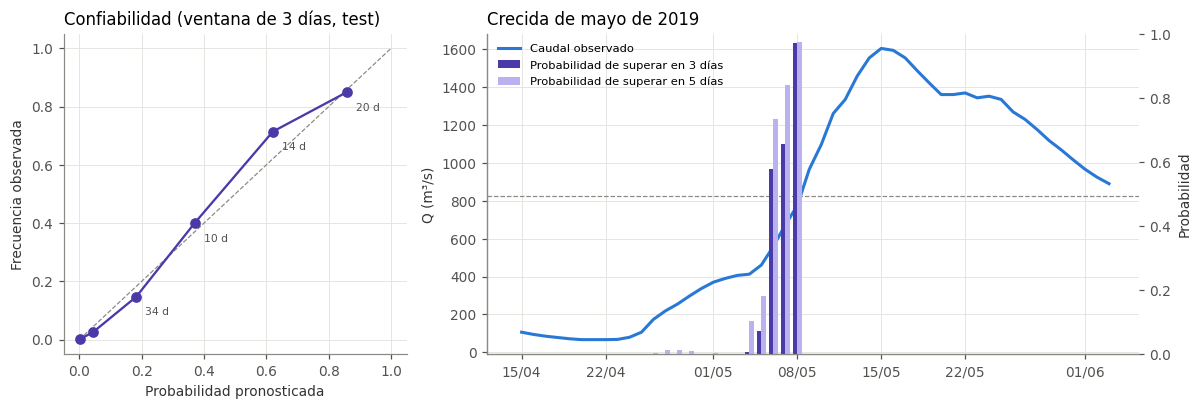

,Q,prob_3d,prob_5d
2019-05-02,390.764,0.001,0.001
2019-05-03,406.476,0.000,0.001
2019-05-04,412.812,0.007,0.103
2019-05-05,461.257,0.071,0.182
2019-05-06,559.557,0.578,0.734
2019-05-07,674.156,0.655,0.840
2019-05-08,774.959,0.970,0.973
2019-05-09,967.291,0.977,0.974
2019-05-10,1097.927,0.973,0.974


In [38]:
ev3 = (max_futuro(3) > U).astype(float).where(max_futuro(3).notna()); ite_ = ev3.notna() & okx & (serie.Q <= U) & TEST
pr, o = PROB_AL[3][ite_], ev3[ite_]
g = pd.cut(pr, [0, 0.02, 0.1, 0.3, 0.5, 0.7, 1.0], include_lowest=True)
conf = pd.DataFrame({'prob_media': pr.groupby(g).mean(), 'frecuencia_obs': o.groupby(g).mean(), 'dias': o.groupby(g).size()})
R['alerta']['confiabilidad_3'] = conf.reset_index(drop=True).round(4).to_dict(orient='records')
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.9]})
axs[0].plot([0, 1], [0, 1], color=C_PERS, lw=0.8, ls='--'); axs[0].plot(conf.prob_media, conf.frecuencia_obs, 'o-', color='#4a3aa7')
for _, r_ in conf[conf.prob_media > 0.1].iterrows():
    axs[0].annotate(f'{int(r_.dias)} d', (r_.prob_media, r_.frecuencia_obs), xytext=(6, -12), textcoords='offset points', fontsize=7, color='#52514e')
axs[0].set_xlabel('Probabilidad pronosticada'); axs[0].set_ylabel('Frecuencia observada'); axs[0].set_title('Confiabilidad (ventana de 3 días, test)', loc='left')
v_ = slice('2019-04-15', '2019-06-10'); ax = axs[1]; ax2 = ax.twinx()
ax.plot(serie.Q[v_].index, serie.Q[v_], color=C_OBS, lw=2, label='Caudal observado'); ax.axhline(U, color=C_PERS, ls='--', lw=0.8)
for w, c, dx in [(3, '#4a3aa7', -0.2), (5, '#b9b2ee', 0.2)]:
    pv = PROB_AL[w][v_].where(serie.Q[v_] <= U)
    ax2.bar(pv.index + pd.Timedelta(hours=24 * dx), pv, color=c, width=0.4, label=f'Probabilidad de superar en {w} días')
ax2.set_ylim(0, 1); ax2.set_ylabel('Probabilidad'); ax2.grid(False)
ax.set_ylabel('Q (m³/s)'); ax.set_title('Crecida de mayo de 2019', loc='left'); ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d/%m'))
h1_, l1_ = ax.get_legend_handles_labels(); h2_, l2_ = ax2.get_legend_handles_labels(); ax.legend(h1_ + h2_, l1_ + l2_, fontsize=7.5, loc='upper left')
plt.tight_layout(); plt.savefig(f'{FIG}/alerta_probabilidad.png', dpi=150); plt.show()
pd.DataFrame({'Q': serie.Q['2019-05-02':'2019-05-10'], 'prob_3d': PROB_AL[3]['2019-05-02':'2019-05-10'], 'prob_5d': PROB_AL[5]['2019-05-02':'2019-05-10']}).round(3)

Todas las alertas basadas en el modelo detectan 13 de las 14 crecidas del test (la restante fue un pico de un día causado por lluvia posterior a la emisión); la regla de extrapolar la tendencia detecta lo mismo con tres a cinco veces más falsas alarmas.

- Ventana de 3 días: el clasificador da la mayor anticipación (~2,5 días) con menos de una falsa alarma por año, y sus probabilidades son confiables (las frecuencias observadas siguen a las probabilidades). Se adopta como criterio de alerta.
- Ventana de 5 días: el clasificador, con el valor de corte elegido en el entrenamiento (0,10), genera demasiadas falsas alarmas; la regresión (algún pronóstico a 1, 3 o 5 días supera el umbral) da ~3 días de anticipación con menos de una falsa alarma por año. Se adopta como aviso temprano.

Esquema operativo resultante: aviso temprano a 5 días (regresión) y alerta a 3 días (probabilidad del clasificador); la magnitud se comunica con el pronóstico y su intervalo de confianza.

## 16. Explicabilidad (SHAP, h = 3)

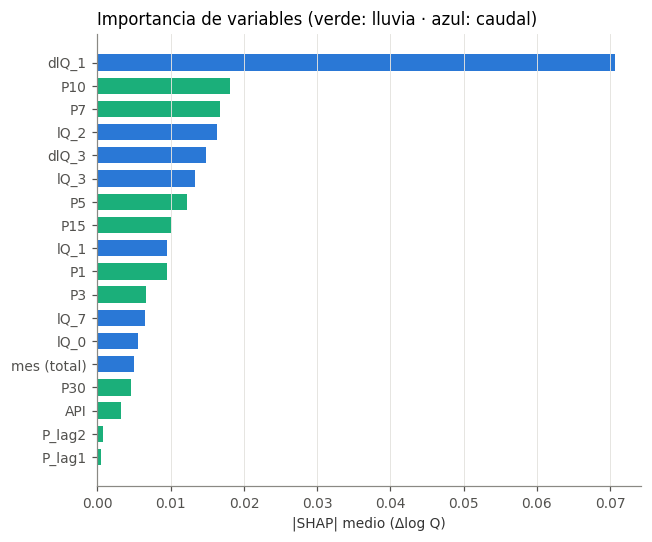

In [39]:
pipe_final = finales[H]
idx_te = ite[ite].index
Xt = pipe_final.named_steps['prep'].transform(X.loc[idx_te, ALL_COLS])
nombres = [n.split('__')[1] for n in pipe_final.named_steps['prep'].get_feature_names_out()]
explainer = shap.TreeExplainer(pipe_final.named_steps['modelo'])
sv = explainer.shap_values(Xt)
imp = pd.Series(np.abs(sv).mean(0), index=nombres)
imp_mes = imp[[c for c in nombres if c.startswith('mes_')]].sum()
imp = pd.concat([imp[[c for c in nombres if not c.startswith('mes_')]], pd.Series({'mes (total)': imp_mes})]).sort_values()
R['shap'] = imp.sort_values(ascending=False).round(5).to_dict()
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(imp.index, imp.values, color=[C_P if c.startswith(('P', 'API')) else C_OBS for c in imp.index], height=0.7)
ax.set_xlabel('|SHAP| medio (Δlog Q)'); ax.grid(axis='y', visible=False)
ax.set_title('Importancia de variables (verde: lluvia · azul: caudal)', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/shap_importancia.png', dpi=150); plt.show()

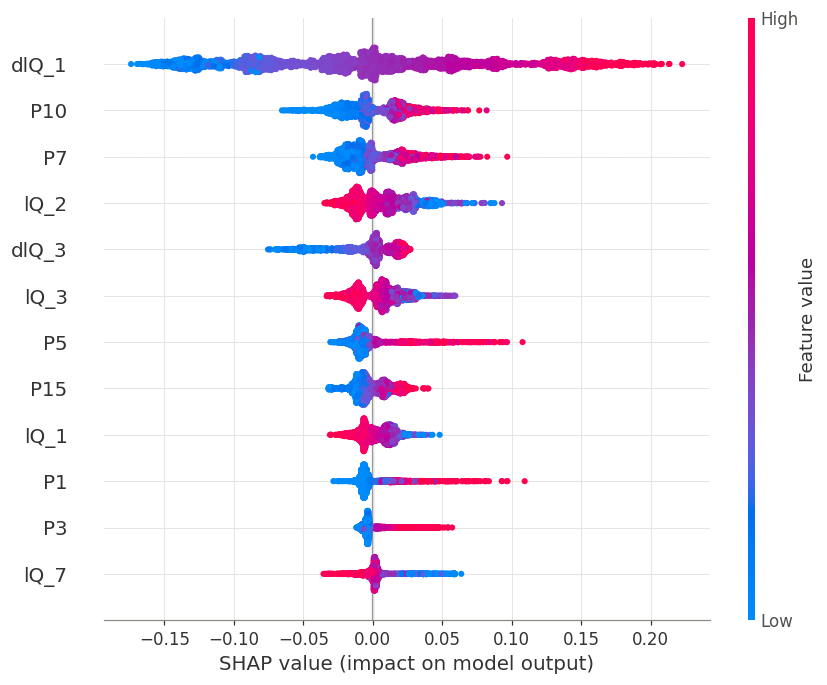

In [40]:
shap.summary_plot(sv, Xt, feature_names=nombres, max_display=12, show=False)
plt.tight_layout(); plt.savefig(f'{FIG}/shap_resumen.png', dpi=150); plt.show()

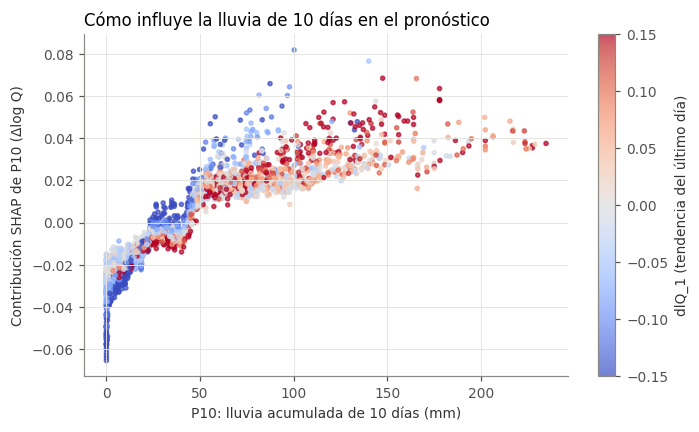

In [41]:
# Dependencia: efecto de P10 según la tendencia del caudal
i_p10, i_dq = nombres.index('P10'), nombres.index('dlQ_1')
fig, ax = plt.subplots(figsize=(6.5, 4))
sc = ax.scatter(X.loc[idx_te, 'P10'], sv[:, i_p10], c=X.loc[idx_te, 'dlQ_1'].clip(-0.15, 0.15), cmap='coolwarm', s=7, alpha=0.7)
plt.colorbar(sc, ax=ax, label='dlQ_1 (tendencia del último día)')
ax.set_xlabel('P10: lluvia acumulada de 10 días (mm)'); ax.set_ylabel('Contribución SHAP de P10 (Δlog Q)')
ax.set_title('Cómo influye la lluvia de 10 días en el pronóstico', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/shap_dependencia_P10.png', dpi=150); plt.show()

## 17. Retorno de la inversión (ROI) en tres escenarios

Beneficio: crecidas alertadas con anticipación × daño evitable por crecida (retiro de ganado y bienes ribereños, cierre preventivo de accesos, preparación de la ruta PY01). Costo: implementación + operación anual + falsas alarmas. Las frecuencias de crecidas alertadas y de falsas alarmas salen del test (alerta a 3 días). Los montos son supuestos de referencia, a reemplazar por los de la autoridad de gestión de riesgo.

`ROI = (beneficio − costo) / costo`, a 5 años.

In [42]:
anos_test = TEST.sum() / 365.25
cl3 = T_EV[(T_EV.ventana == 3) & (T_EV.metodo == 'Clasificador (probabilidad)')].iloc[0]
crec_ano, fa_ano = cl3.detectados / anos_test, cl3.falsas_alarmas / anos_test
ESC = pd.DataFrame({
    'Conservador': {'daño evitado por crecida (USD)': 15000, 'costo por falsa alarma (USD)': 3000, 'implementación (USD)': 12000, 'operación anual (USD)': 6000},
    'Base':        {'daño evitado por crecida (USD)': 40000, 'costo por falsa alarma (USD)': 2000, 'implementación (USD)': 12000, 'operación anual (USD)': 4000},
    'Optimista':   {'daño evitado por crecida (USD)': 80000, 'costo por falsa alarma (USD)': 1000, 'implementación (USD)': 12000, 'operación anual (USD)': 3000}}).T
N_ANOS = 5
def roi(e):
    benef = N_ANOS * crec_ano * e['daño evitado por crecida (USD)']
    costo = e['implementación (USD)'] + N_ANOS * (e['operación anual (USD)'] + fa_ano * e['costo por falsa alarma (USD)'])
    return pd.Series({'beneficio 5 años (USD)': benef, 'costo 5 años (USD)': costo, 'beneficio neto (USD)': benef - costo, 'ROI': (benef - costo) / costo})
ROI = ESC.join(ESC.apply(roi, axis=1))
R['roi'] = {'crecidas_alertadas_por_ano': float(crec_ano), 'falsas_alarmas_por_ano': float(fa_ano), 'anos': N_ANOS, 'escenarios': ROI.round(3).to_dict(orient='index')}
print(f'Crecidas alertadas por año: {crec_ano:.2f} · falsas alarmas por año: {fa_ano:.2f}')
ROI.round(2)

Crecidas alertadas por año: 1.22 · falsas alarmas por año: 0.94


,daño evitado por crecida (USD),costo por falsa alarma (USD),implementación (USD),operación anual (USD),beneficio 5 años (USD),costo 5 años (USD),beneficio neto (USD),ROI
Conservador,15000,3000,12000,6000,91617.89,56095.06,35522.83,0.63
Base,40000,2000,12000,4000,244314.38,41396.71,202917.67,4.90
Optimista,80000,1000,12000,3000,488628.76,31698.35,456930.41,14.41


## 18. Guardado del modelo e inferencia

In [43]:
resumen_app = {'metricas': metricas_df.round(4).to_dict(orient='index'), 'persistencia': base.round(4).to_dict(orient='index'),
               'comparacion': tab_comp.round(4).to_dict(orient='index'), 'ablacion_skill': tab_skill.round(4).to_dict(orient='index'),
               'shap': R['shap'], 'alcance': R['alcance'], 'cobertura': R['cobertura'], 'desfase': R['desfase'], 'alerta': R['alerta'],
               'corr_retardo': [float(c) for c in cc[:15]], 'Pmed_anual': float(Pmed.resample('YE').sum(min_count=330).mean()),
               'n_train': int(datos_h(3)[1].sum()), 'n_test': int(datos_h(3)[2].sum())}
bundle = {'modelos': finales, 'cuantiles': CUANT, 'alerta': {3: CLASIF[3]}, 'aviso_temprano': 'regresión central: algún pronóstico a 1, 3 o 5 días supera el umbral', 'resumen': resumen_app, 'features': ALL_COLS, 'ventanas': VENT, 'api_k': API_K,
          'horizontes': HORIZ, 'umbral_Q10_permanencia': float(Q90), 'umbral_estiaje': PERM[75], 'permanencia': PERM,
          'objetivo': 'log Q(t+h) - log Q(t)', 'hiperparametros': MEJORES, 'periodo_train': '1974-2002', 'periodo_test': '2013-2023',
          'area_km2': float(A_KM2), 'pesos_thiessen': w_full.round(4).to_dict()}
joblib.dump(bundle, 'model.pkl', compress=3)
print(f'model.pkl guardado ({os.path.getsize("model.pkl") / 1e6:.2f} MB)')

model.pkl guardado (1.60 MB)


In [44]:
# Prueba de carga e inferencia: emisión del 7 de mayo de 2019 (crecida del período de test)
cargado = joblib.load('model.pkl')
t0 = pd.Timestamp('2019-05-07')
hist = serie.loc[t0 - pd.Timedelta(days=60):t0, ['Pmed', 'Q']]
Xh = construir_features(hist).iloc[[-1]][cargado['features']]
q_hoy = hist.Q.iloc[-1]
print(f'Emisión: mañana del {(t0 + pd.Timedelta(days=1)).date()} con datos del {t0.date()} · Q = {q_hoy:,.0f} m³/s')
pron = {}
for h, mdl in cargado['modelos'].items():
    qf = q_hoy * np.exp(mdl.predict(Xh)[0]); cq = cargado['cuantiles'][h]; pron[h] = qf
    lo = q_hoy * np.exp(cq['p05'].predict(Xh)[0] - cq['qhat']); hi = q_hoy * np.exp(cq['p95'].predict(Xh)[0] + cq['qhat'])
    print(f'  t+{h} ({(t0 + pd.Timedelta(days=h)).date()}): {qf:,.0f} m³/s  [IC 90 %: {lo:,.0f} – {hi:,.0f}]  · observado {serie.Q.get(t0 + pd.Timedelta(days=h)):,.0f} m³/s')
print(f'  Aviso temprano (5 días): {"SÍ" if max(pron.values()) > Q90 else "no"} — máximo pronosticado {max(pron.values()):,.0f} m³/s')
for w, c in cargado['alerta'].items():
    p = c['modelo'].predict_proba(Xh)[0, 1]
    print(f'  Probabilidad de superar {Q90:,.0f} m³/s en {w} días: {p:.0%} ({"ALERTA" if p >= c["umbral_prob"] else "sin alerta"})')

Emisión: mañana del 2019-05-08 con datos del 2019-05-07 · Q = 674 m³/s
  t+1 (2019-05-08): 756 m³/s  [IC 90 %: 651 – 847]  · observado 775 m³/s
  t+3 (2019-05-10): 877 m³/s  [IC 90 %: 580 – 1,118]  · observado 1,098 m³/s
  t+5 (2019-05-12): 974 m³/s  [IC 90 %: 530 – 1,352]  · observado 1,336 m³/s
  Aviso temprano (5 días): SÍ — máximo pronosticado 974 m³/s
  Probabilidad de superar 823 m³/s en 3 días: 65% (ALERTA)


## 19. Muestra de datos (100 filas)

Ventana de 100 días alrededor de la crecida de mayo de 2019 (período de test): precipitación por estación, Pmed y caudal en Villa Florida (Q). Es el archivo de ejemplo de la aplicación.

In [45]:
ini = pd.Timestamp('2019-05-15') - pd.Timedelta(days=73)
muestra = serie[['Pmed', 'Q']].join(P).loc[ini:ini + pd.Timedelta(days=99)].round(3)
muestra.to_csv('datos_muestra.csv', index_label='fecha')
print(muestra.shape); muestra.head()

(100, 10)


,Pmed,Q,Paraguari,Villarrica,Coronel_Oviedo,Quyquyho,Pilar,San_Juan_Bautista,Caazapa,Encarnacion
2019-03-03,0.000,34.167,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-03-04,0.000,35.237,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-03-05,9.614,37.384,0.0,8.0,0.0,0.0,8.5,0.0,8.0,77.8
2019-03-06,2.672,36.309,7.6,0.0,0.0,6.0,0.5,1.3,0.0,20.7
2019-03-07,12.726,34.167,0.0,9.1,0.0,0.0,0.0,0.5,11.6,98.9


In [46]:
import json
R['persistencia'] = base.round(4).to_dict(orient='index')
R['comparacion'] = comp.round(4).to_dict(orient='records')
R['ponderacion'] = pond.round(4).to_dict(orient='index')
R['ablacion_skill'] = tab_skill.round(4).to_dict(orient='index')
R['ganancia'] = ganancia.round(4).to_dict(orient='index')
R['optimizacion'] = {'mejores': MEJORES, 'tuned': {k: float(v) for k, v in m_tuned.items()}, 'defecto': m_def.astype(float).round(4).to_dict()}
R['general'] = {'Q90': float(Q90), 'area_km2': float(A_KM2), 'pesos': w_full.round(4).to_dict(), 'combinaciones': len(_cache),
                'Pmed_anual': float(Pmed.resample('YE').sum(min_count=330).mean()), 'corr_retardo': [float(c) for c in cc[:12]],
                'n_train': int(datos_h(3)[1].sum()), 'n_test': int(datos_h(3)[2].sum()), 't_pico': str(t_pico.date()), 'evento_eval': str(ev_eval.date())}
os.makedirs('resultados', exist_ok=True)
json.dump(R, open('resultados/resultados.json', 'w'), indent=1, default=str, ensure_ascii=False)
print('resultados/resultados.json guardado')

resultados/resultados.json guardado


## 20. Conclusiones

1. La lluvia media de la cuenca se calcula con Thiessen dinámico, tratando los −1 como faltantes y corrigiendo la duplicación de las series de Quyquyho y Caazapá (1974–2016).
2. LightGBM (gradient boosting) supera a la persistencia, a Ridge y a Random Forest en los tres horizontes; empata con XGBoost y se elige por su menor costo de entrenamiento.
3. El pronóstico a 1, 3 y 5 días reduce el error cuadrático de la persistencia en 46 %, 54 % y 56 %; para caudales medios y altos el error típico es de ~2 % a 1 día, ~5 % a 3 días y ~10 % a 5 días. En las subidas se queda corto (~10 %) y llega con atraso (1 día a 1–3 días; 3 días a 5 días, frente a 5 de la persistencia).
4. Los intervalos del 90 %, recalibrados con datos recientes, cubren el 90 %, 88 % y 86 % de las observaciones a 1, 3 y 5 días en un período independiente (2016–2023), y más del 96 % en caudales altos.
5. Como alerta, el sistema detecta 13 de las 14 crecidas que superaron el caudal de 10 % de permanencia en 2013–2023: aviso temprano a 5 días (regresión, ~3 días de anticipación) y alerta a 3 días (probabilidad del clasificador, ~2,5 días), ambos con menos de una falsa alarma por año.
6. Los estiajes no se pronostican: tienen mayor variabilidad relativa, mayor error y un régimen que cambió en el período reciente.
7. Con supuestos de referencia, el retorno de la inversión a 5 años es positivo en los tres escenarios (conservador, base y optimista).
8. La mejora siguiente no depende del algoritmo sino de medir los afluentes intermedios (Tebicuary-mí y Pirapó).